In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 927.3/927.3 kB 12.9 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, jaccard_score
from sklearn.metrics import jaccard_score
from sklearn.model_selection import train_test_split
from torchmetrics import JaccardIndex, Accuracy, F1Score, Precision, Recall  # Import all necessary

# Define U-Net architecture
class UNet(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        # Encoder (downsampling)
        self.enc1 = self.conv_block(n_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)

        # Decoder (upsampling)
        self.dec1 = self.upconv(512, 256)
        self.dec2 = self.upconv(256, 128)
        self.dec3 = self.upconv(128, 64)
        self.dec4 = self.upconv(64, 64)
        self.dec5 = nn.Conv2d(64, n_classes, kernel_size=1)

        # Initialize with kaiming normal
        self.initialize_weights()

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d) or isinstance(module, nn.ConvTranspose2d):
              nn.init.kaiming_normal_(module.weight)


    def conv_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def upconv(self, in_ch, out_ch):
        return nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        # Encoder
        # print(x.shape)
        e1 = self.enc1(x)
        # print(e1.shape)
        e2 = self.enc2(e1)
        # print(e2.shape)
        e3 = self.enc3(e2)
        # print(e3.shape)
        e4 = self.enc4(e3)
        # print(e4.shape)

        # Decoder
        d1 = self.dec1(e4)
        # print(d1.shape)
        d2 = self.dec2(d1)
        # print(d2.shape)
        d3 = self.dec3(d2)
        # print(d3.shape)
        d4 = self.dec4(d3)
        # print(d4.shape)
        out = self.dec5(d4)
        # print(out.shape)

        return torch.sigmoid(out)

class LakeDataset(Dataset):
    def __init__(self, image_folder, mask_folder, transform=None):
        self.image_folder = image_folder
        self.mask_folder = mask_folder
        self.transform = transform
        self.file_names = [f for f in os.listdir(image_folder) if f.endswith('.npy')]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_name = self.file_names[idx]
        image_path = os.path.join(self.image_folder, file_name)
        mask_path = os.path.join(self.mask_folder, file_name)

        image = np.load(image_path)
        mask = np.load(mask_path)

        # Check the shape of the loaded data
        # print(f"Image shape: {image.shape}")
        # print(f"Mask shape: {mask.shape}")

        # Convert to grayscale if needed
        if image.shape == (64, 64, 3):
            image = np.transpose(image,(2,0,1))  # Transpose to (3, 64, 64)

        # Ensure image shape is (1, 64, 64)
        #image = image.reshape((1, 64, 64))
        if mask.shape == (64, 64, 1):
            image = np.transpose(mask,(2,0,1))
        # Normalize mask values
        mask = mask.astype(np.float32) / 255.0  # Assuming masks are in 0-255 range

        # Convert to torch tensors
        image = torch.from_numpy(image).float()
        mask = torch.from_numpy(mask).float()

        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        return image, mask, file_name  # Return file name for identification

# Training function
def train(model, dataloader, criterion, optimizer, device):
    model.train()
    for images, masks, _ in dataloader:
        images, masks = images.to(device), masks.to(device)

        # Use bilinear interpolation for resizing the mask
        # masks = torch.nn.functional.interpolate(masks, size=(32, 32), mode='bilinear', align_corners=False)
        optimizer.zero_grad()
        outputs = model(images)
        outputs=torch.squeeze(outputs)
        # print(masks.shape)
        # print(outputs.shape)
        loss = criterion(outputs, masks)
        loss.backward()

        # Gradient clipping (add this line)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1)  # Adjust clip value if needed

        optimizer.step()

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    iou_metric = JaccardIndex(task="binary")  # Specify 'binary' task
    accuracy_metric = Accuracy(task="binary")  # Add 'task="binary"'
    f1_metric = F1Score(task="binary")
    precision_metric = Precision(task="binary")
    recall_metric = Recall(task="binary")

    with torch.no_grad():
        for images, masks, _ in dataloader:
            images, masks = images.to(device), masks.to(device)
            # masks = torch.nn.functional.interpolate(masks, size=(32, 32), mode='bilinear', align_corners=False)
            outputs = model(images)
            outputs=torch.squeeze(outputs)
            loss = criterion(outputs, masks)
            total_loss += loss.item()

            # Threshold predictions AND target masks
            predictions = (outputs > 0.5).float()
            masks = (masks > 0.5).float()  # Threshold target masks

            # Calculate IoU using torchmetrics
            iou = iou_metric(predictions, masks)

            # Calculate other metrics
            accuracy = accuracy_metric(predictions, masks)
            f1 = f1_metric(predictions, masks)
            precision = precision_metric(predictions, masks)
            recall = recall_metric(predictions, masks)

    # Calculate metrics
    test_loss = total_loss / len(dataloader)

    return test_loss, accuracy.item(), f1.item(), recall.item(), precision.item(), iou.item()

# Main execution
def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Hyperparameters
    batch_size = 128
    num_epochs = 200
    learning_rate = 0.0001

    # Data folders
    image_folder = '/content/drive/MyDrive/combined_sent'
    mask_folder = '/content/drive/MyDrive/combined_bin'

    # Define transforms if needed
    transform = None

    # Create dataset
    dataset = LakeDataset(image_folder, mask_folder, transform=transform)

    # Split data into train and test sets
    train_indices, test_indices = train_test_split(
        list(range(len(dataset))), test_size=0.2, random_state=42
    )

    # # Print the test filenames
    # print("Test Filenames:")
    # for idx in test_indices:
    #     print(dataset.file_names[idx])

    train_dataset = torch.utils.data.Subset(dataset, train_indices)
    test_dataset = torch.utils.data.Subset(dataset, test_indices)

    # Create dataloaders
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Initialize model, loss, and optimizer
    model = UNet(n_channels=3, n_classes=1).to(device)  # Assuming single-channel input
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Training loop
    for epoch in range(num_epochs):
        train(model, train_dataloader, criterion, optimizer, device)
        print(f'Epoch {epoch+1}/{num_epochs} completed')

        # Evaluate on test set
        test_loss, accuracy, f1, recall, precision, iou = evaluate(model, test_dataloader, criterion, device)
        print(f'Test Loss: {test_loss:.4f}')
        print(f'Accuracy: {accuracy:.4f}')
       # if epoch%20==0:
        #  torch.save(model.state_dict(), f'/content/drive/MyDrive/new_model/lake_segmentation_model_epoch_{epoch}.pth')

    # Save the model
   # torch.save(model.state_dict(), 'lake_segmentation_model.pth')

if __name__ == '__main__':
    main()


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/combined_sent'

In [ ]:
for i in range(4):
  !mkdir /content/drive/MyDrive/rashid_trials/time/2024/predictions/im_{1+i}

<ipython-input-10-ef6143dc7420>:69: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('/content/drive/MyDrive/lake_segmentation_model_epoch_180.

['patch_5_1.npy', 'patch_5_2.npy', 'patch_5_4.npy', 'patch_5_11.npy', 'patch_6_1.npy', 'patch_6_2.npy', 'patch_6_18.npy', 'patch_6_19.npy', 'patch_7_6.npy', 'patch_7_18.npy', 'patch_8_18.npy', 'patch_8_19.npy', 'patch_8_22.npy', 'patch_8_25.npy', 'patch_9_0.npy', 'patch_9_5.npy', 'patch_9_6.npy', 'patch_9_13.npy', 'patch_9_17.npy', 'patch_9_18.npy', 'patch_9_19.npy', 'patch_9_22.npy', 'patch_10_0.npy', 'patch_10_4.npy', 'patch_10_6.npy', 'patch_10_13.npy', 'patch_10_16.npy', 'patch_10_17.npy', 'patch_10_18.npy', 'patch_10_19.npy', 'patch_10_20.npy', 'patch_10_21.npy', 'patch_10_22.npy', 'patch_10_26.npy', 'patch_10_27.npy', 'patch_11_3.npy', 'patch_11_4.npy', 'patch_11_5.npy', 'patch_11_9.npy', 'patch_11_18.npy', 'patch_11_19.npy', 'patch_11_20.npy', 'patch_11_21.npy', 'patch_11_23.npy', 'patch_11_26.npy', 'patch_11_27.npy', 'patch_11_28.npy', 'patch_12_0.npy', 'patch_12_1.npy', 'patch_12_10.npy', 'patch_12_20.npy', 'patch_12_21.npy', 'patch_12_24.npy', 'patch_12_25.npy', 'patch_12_27.

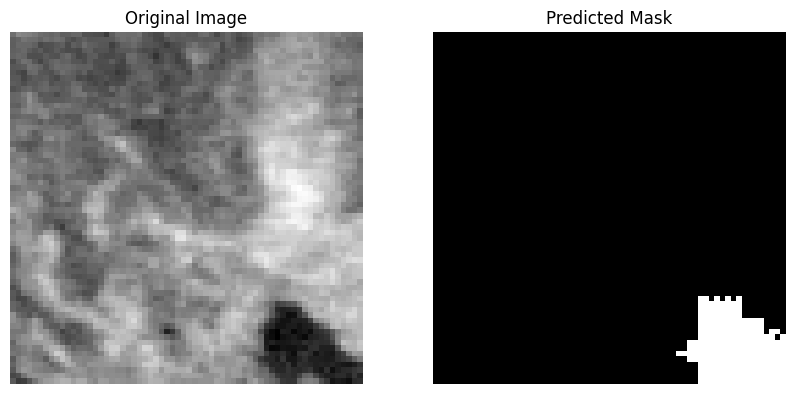

Predicting for patch_5_2.npy...


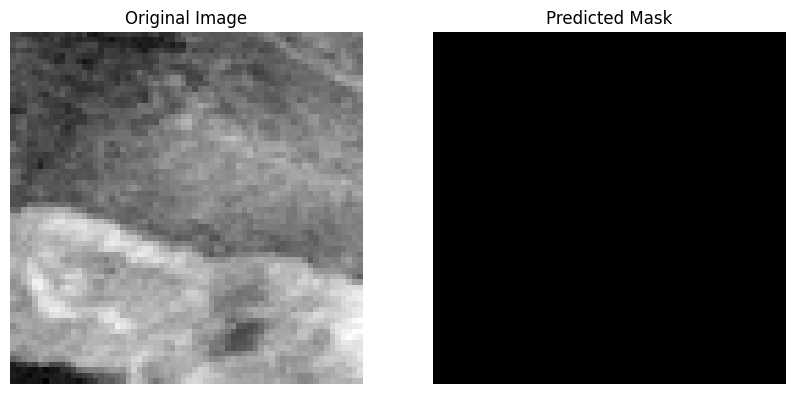

Predicting for patch_5_4.npy...


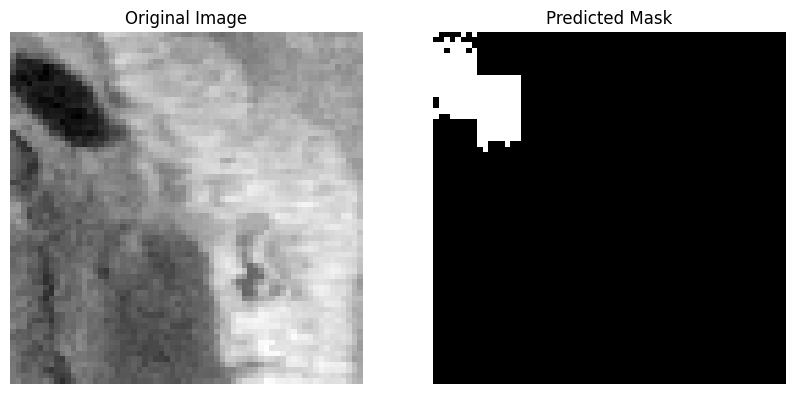

Predicting for patch_5_11.npy...


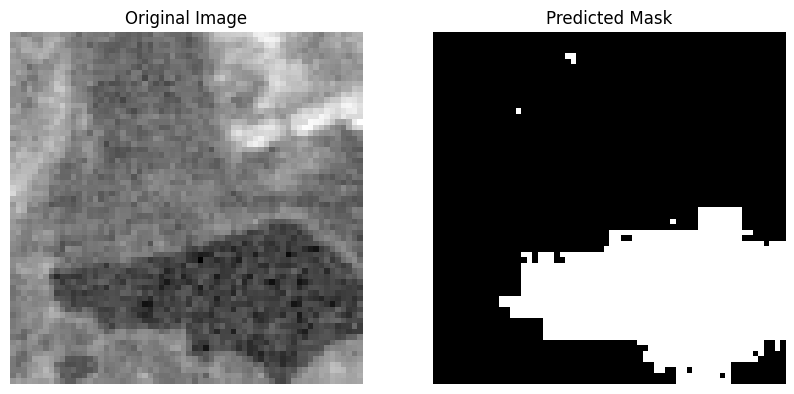

Predicting for patch_6_1.npy...


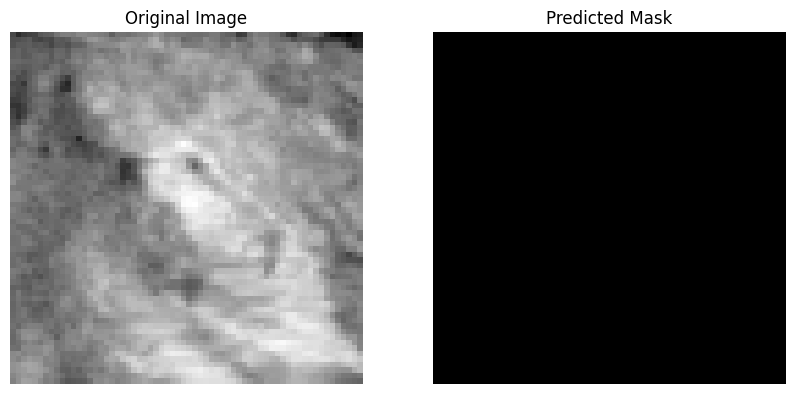

Predicting for patch_6_2.npy...


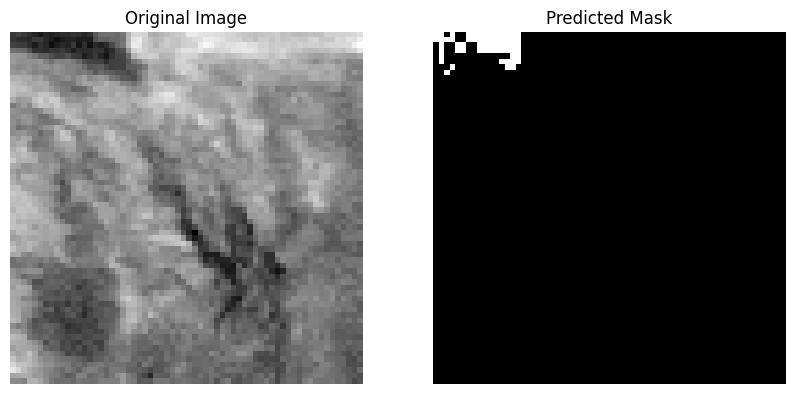

Predicting for patch_6_18.npy...


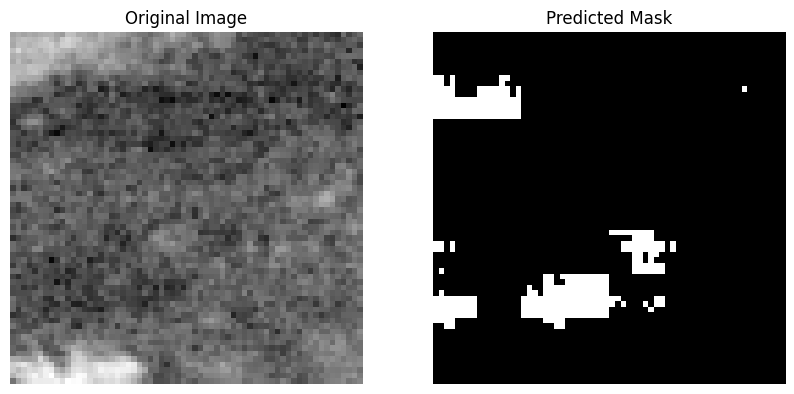

Predicting for patch_6_19.npy...


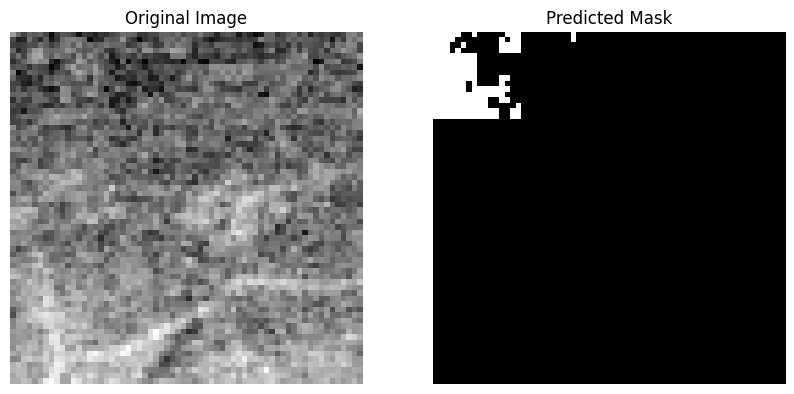

Predicting for patch_7_6.npy...


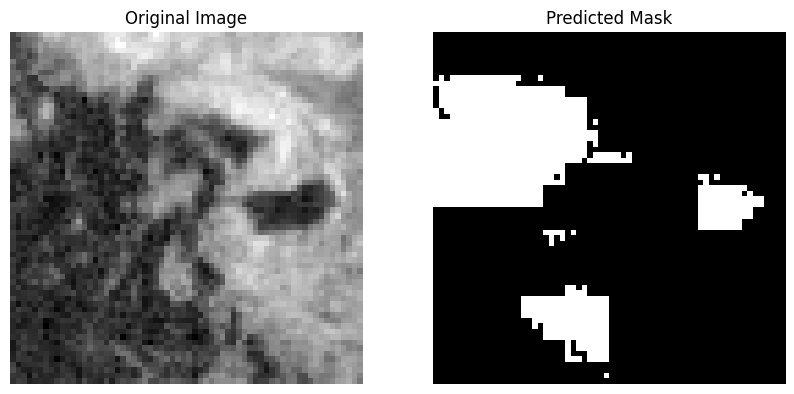

Predicting for patch_7_18.npy...


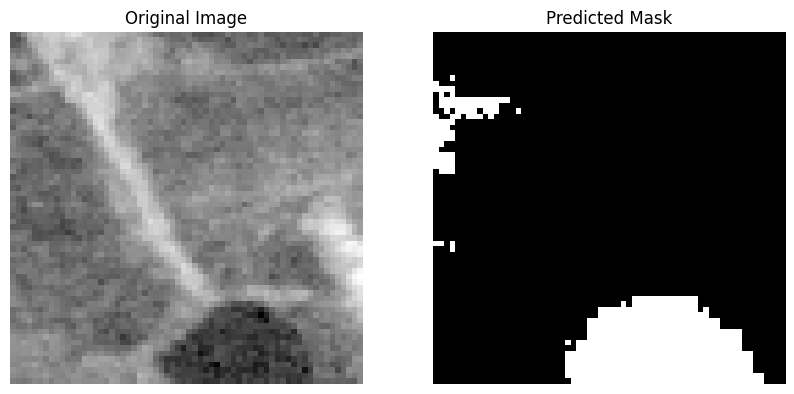

Predicting for patch_8_18.npy...


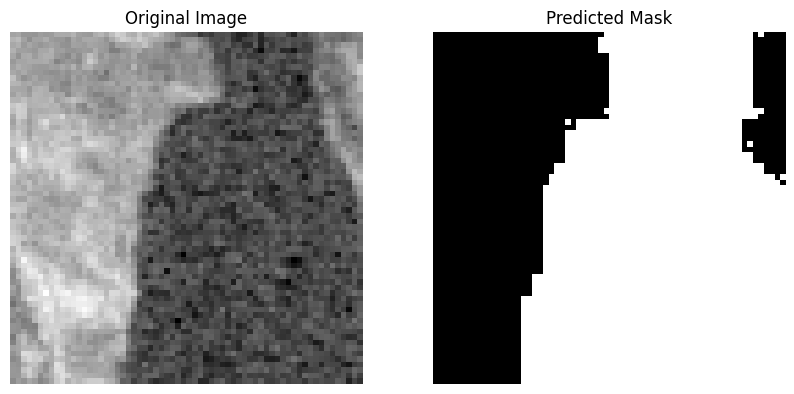

Predicting for patch_8_19.npy...


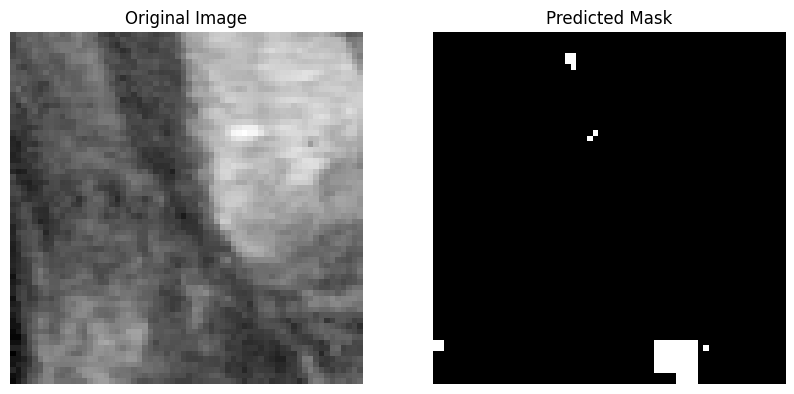

Predicting for patch_8_22.npy...


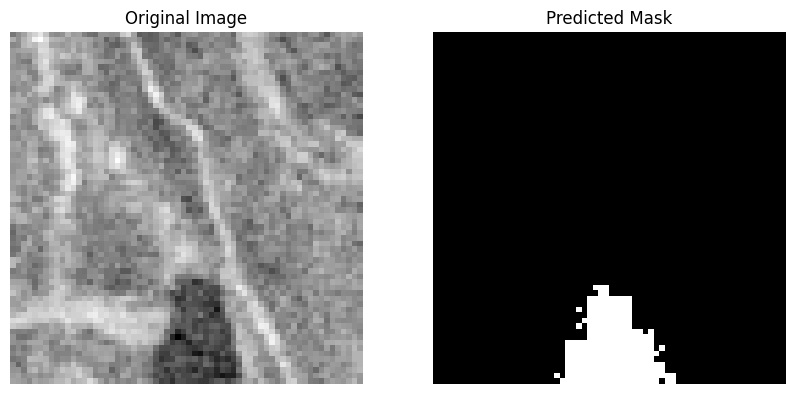

Predicting for patch_8_25.npy...


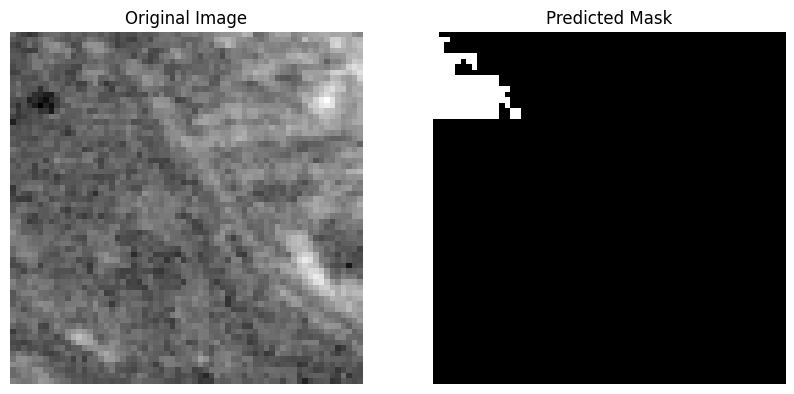

Predicting for patch_9_0.npy...


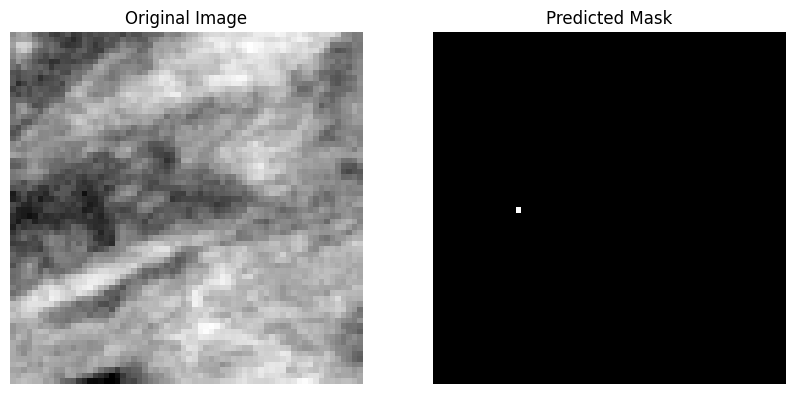

Predicting for patch_9_5.npy...


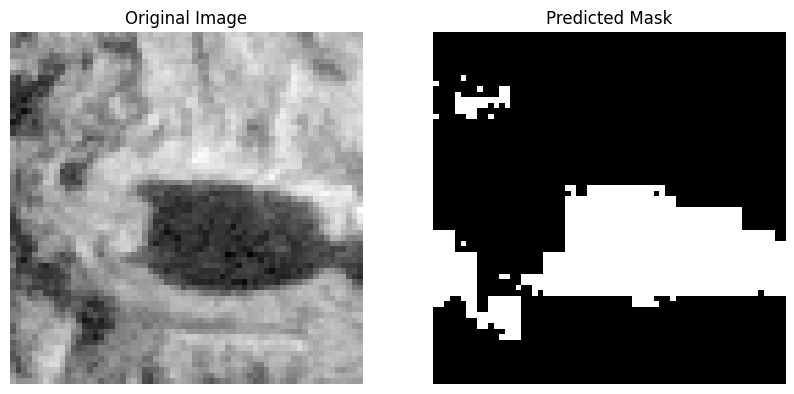

Predicting for patch_9_6.npy...


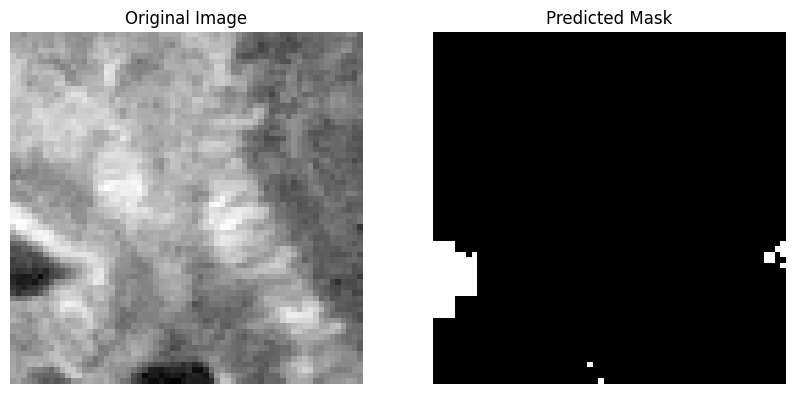

Predicting for patch_9_13.npy...


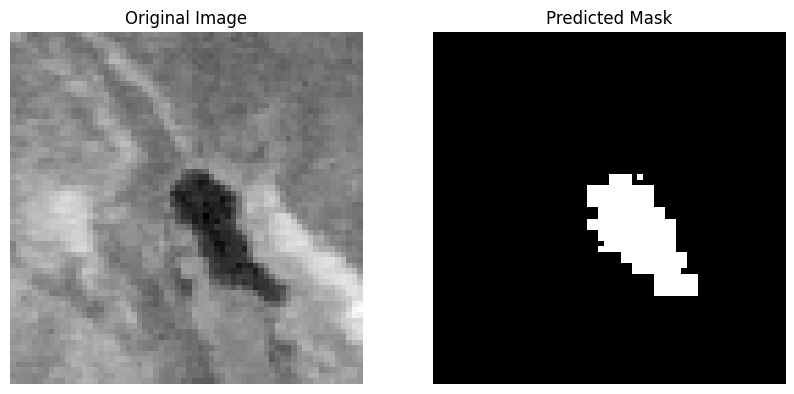

Predicting for patch_9_17.npy...


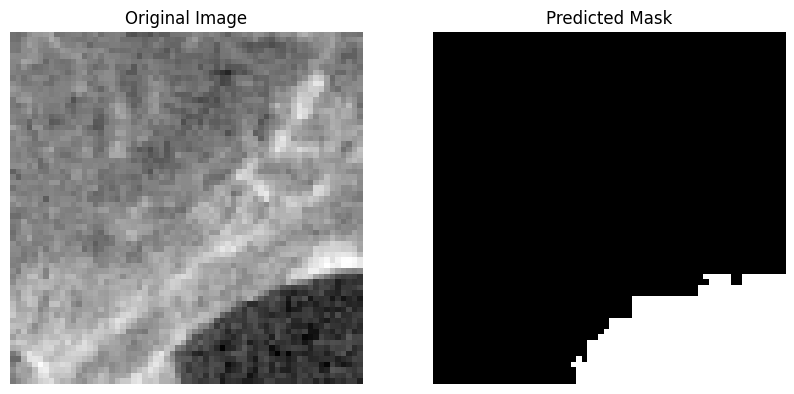

Predicting for patch_9_18.npy...


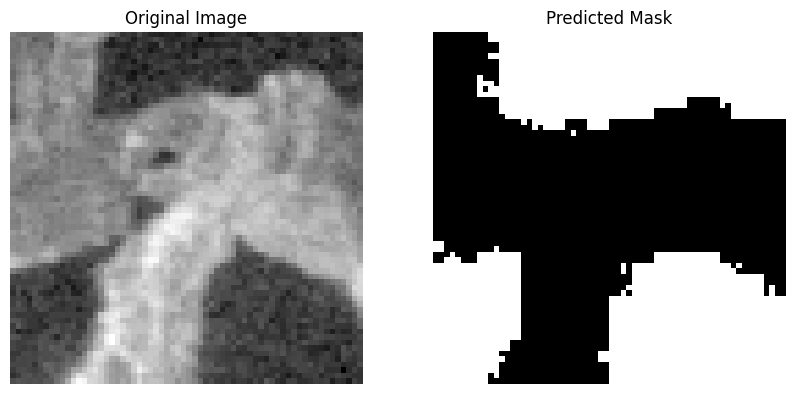

Predicting for patch_9_19.npy...


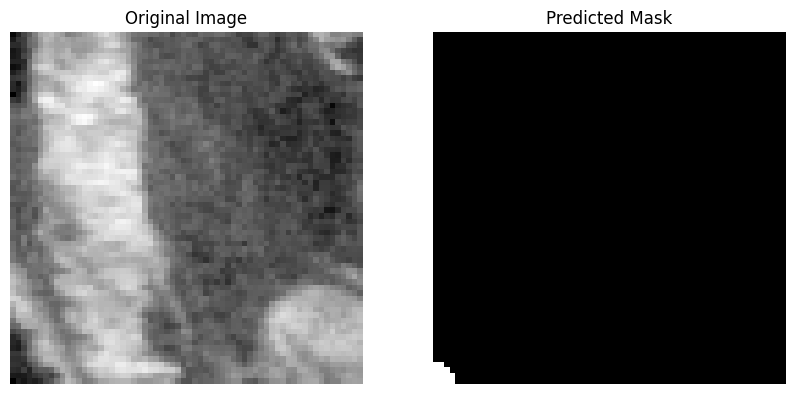

Predicting for patch_9_22.npy...


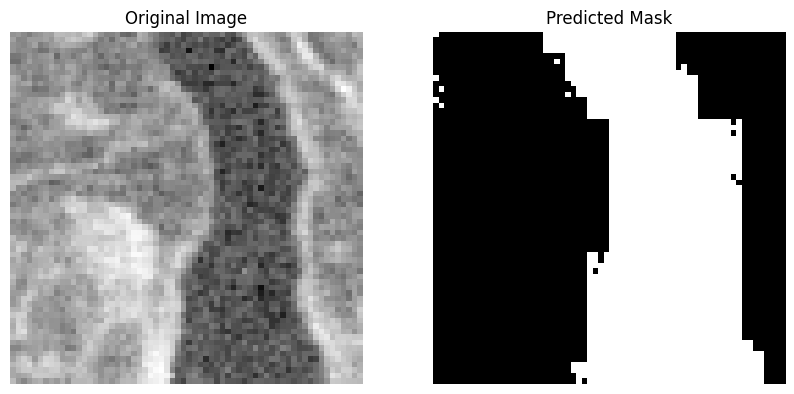

Predicting for patch_10_0.npy...


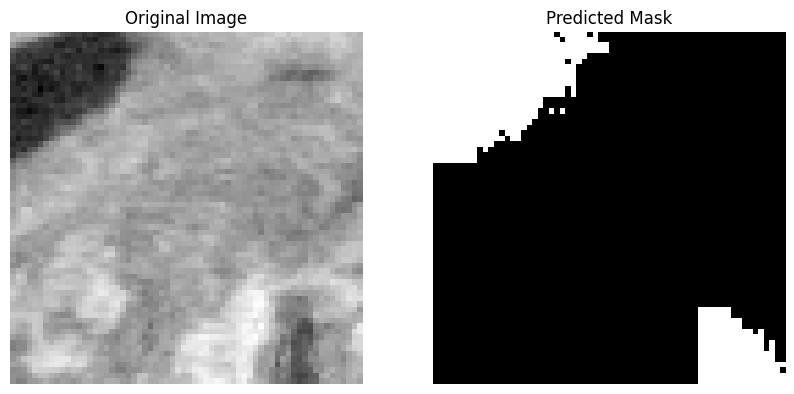

Predicting for patch_10_4.npy...


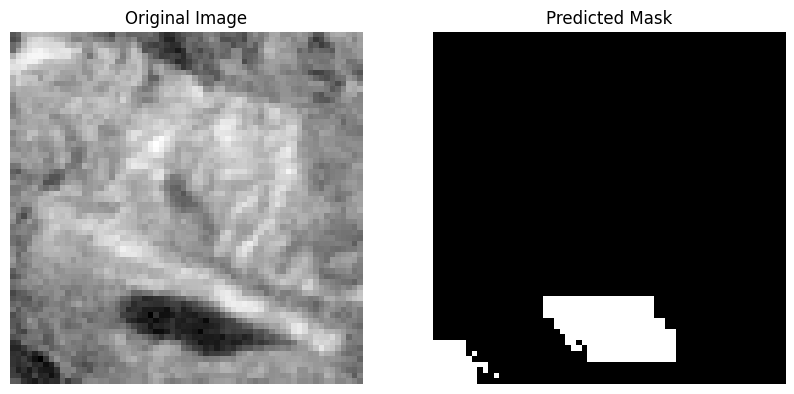

Predicting for patch_10_6.npy...


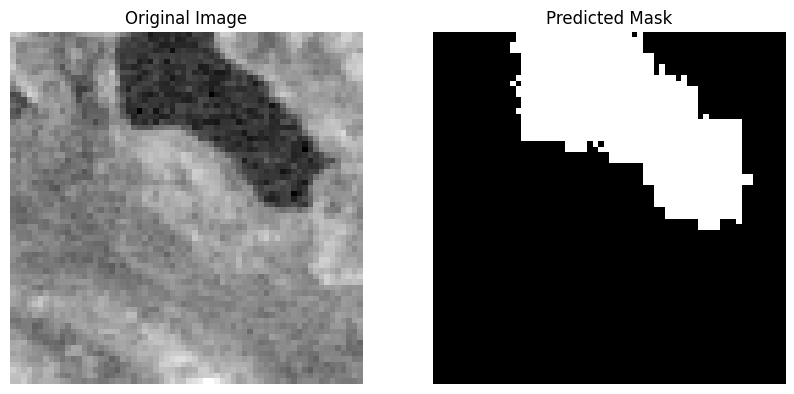

Predicting for patch_10_13.npy...


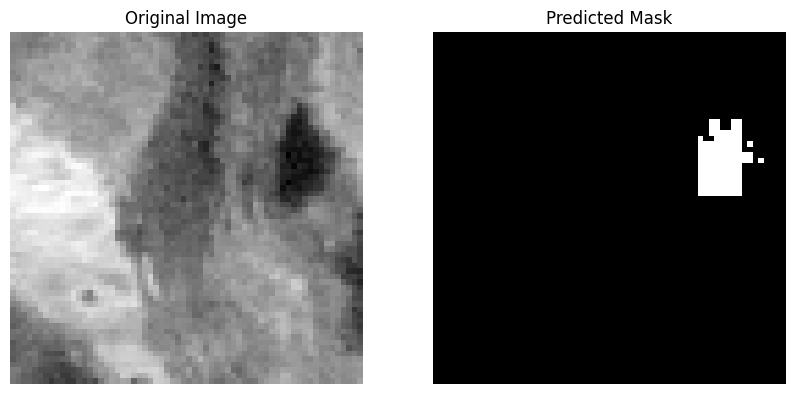

Predicting for patch_10_16.npy...


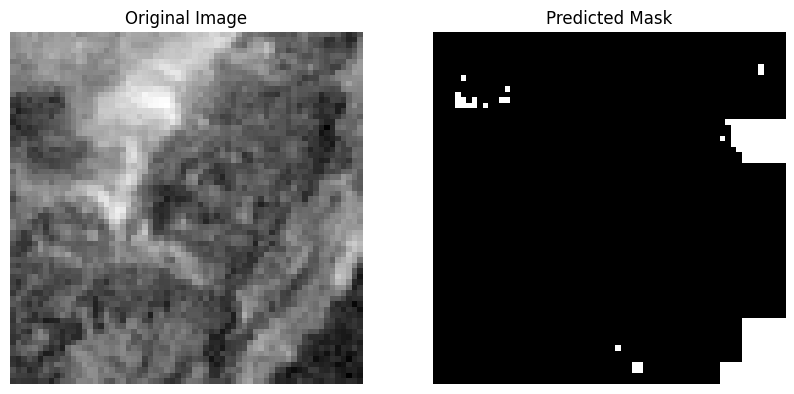

Predicting for patch_10_17.npy...


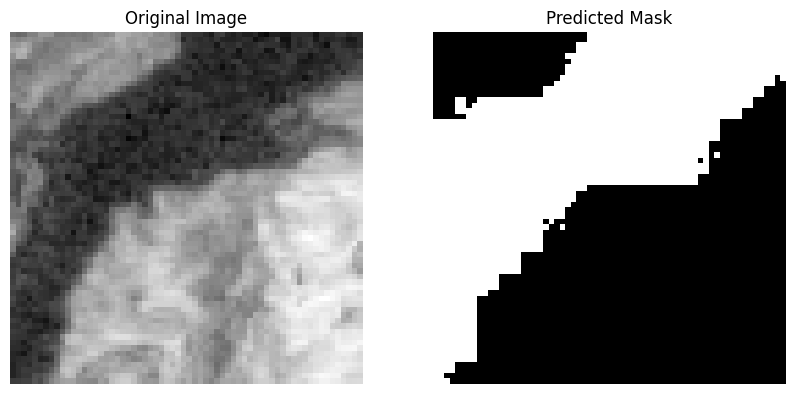

Predicting for patch_10_18.npy...


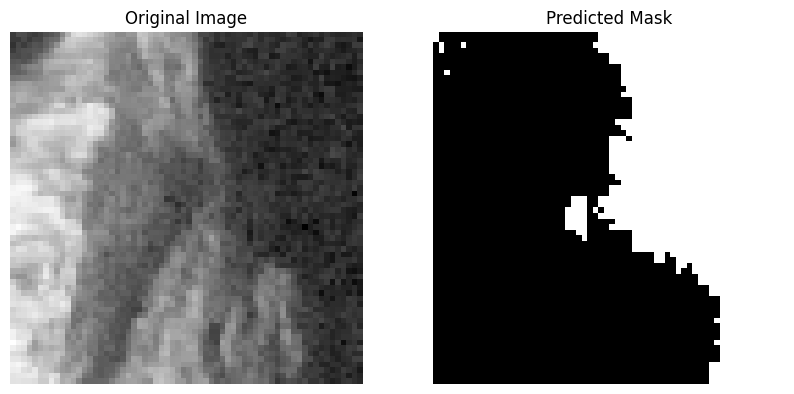

Predicting for patch_10_19.npy...


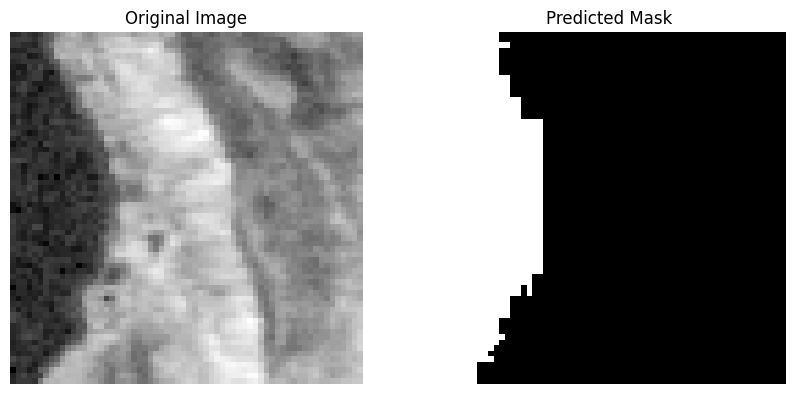

Predicting for patch_10_20.npy...


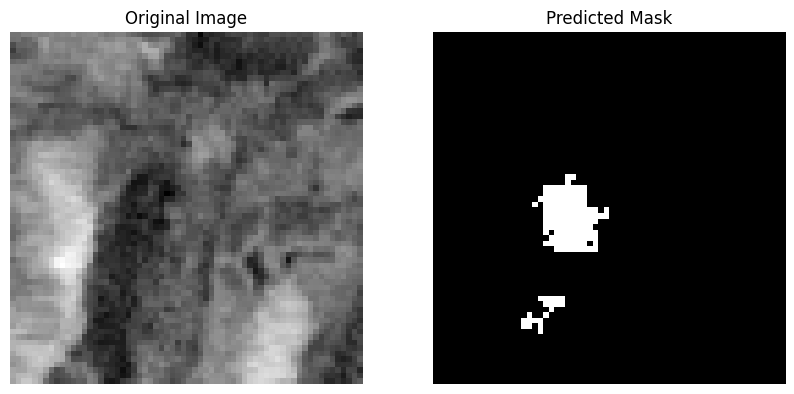

Predicting for patch_10_21.npy...


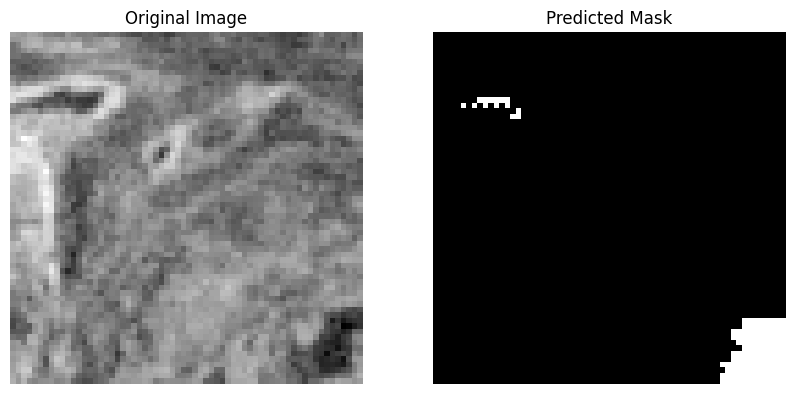

Predicting for patch_10_22.npy...


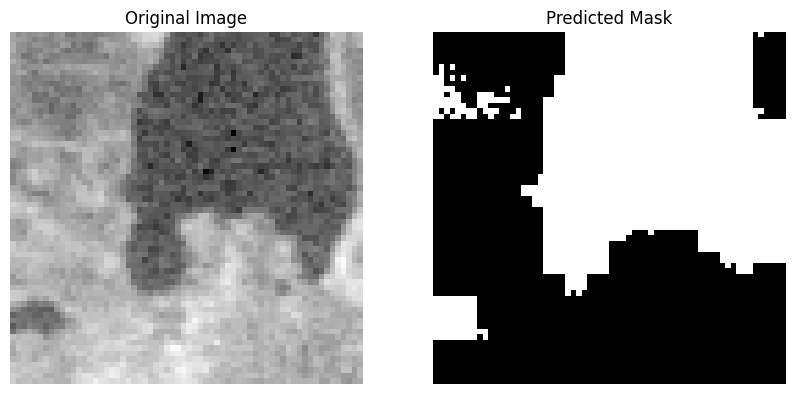

Predicting for patch_10_26.npy...


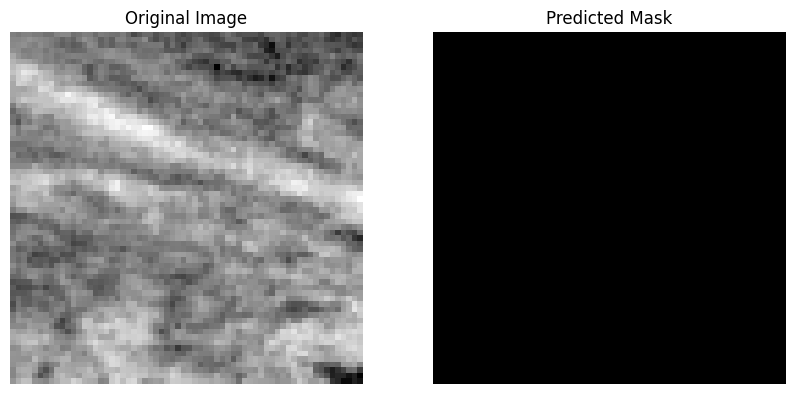

Predicting for patch_10_27.npy...


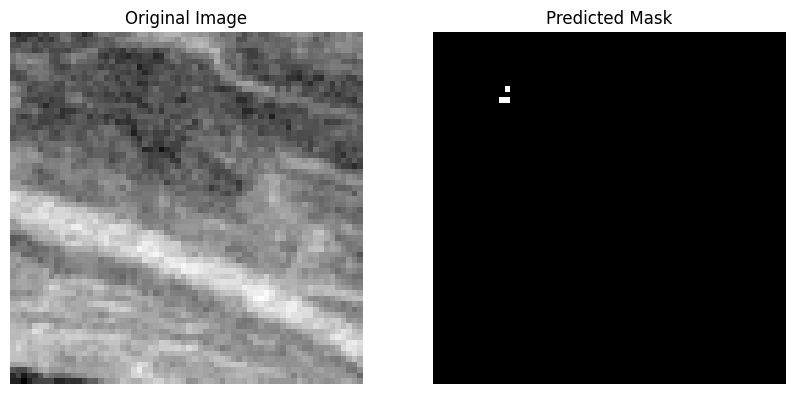

Predicting for patch_11_3.npy...


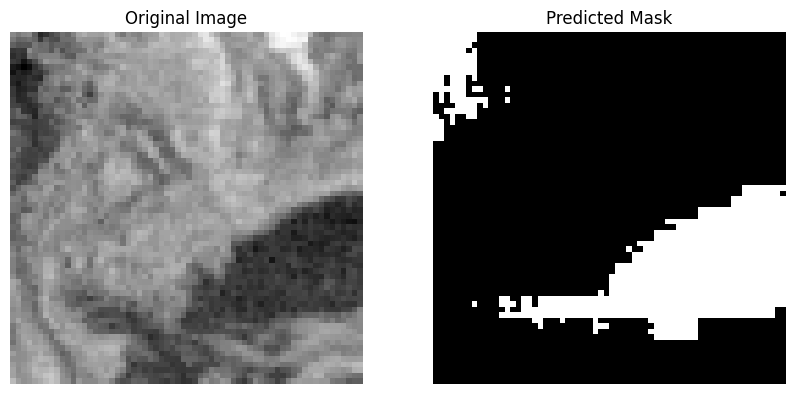

Predicting for patch_11_4.npy...


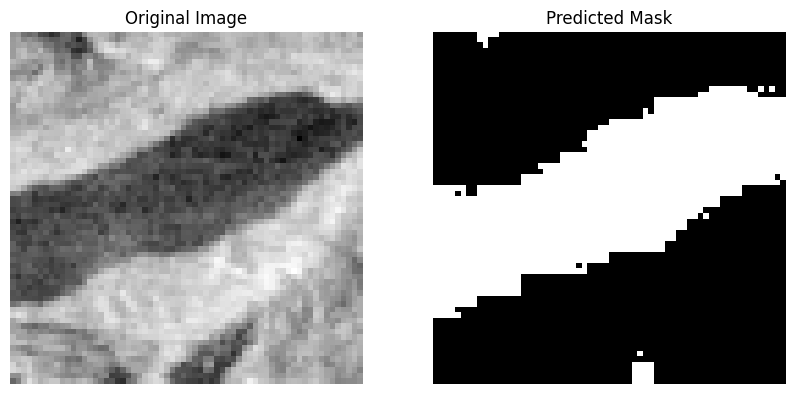

Predicting for patch_11_5.npy...


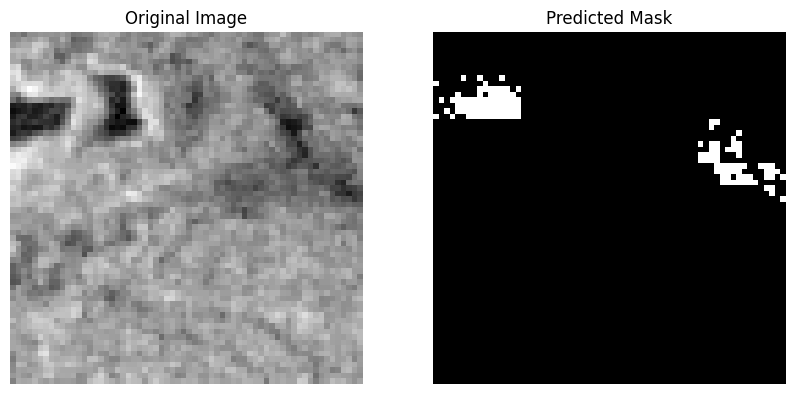

Predicting for patch_11_9.npy...


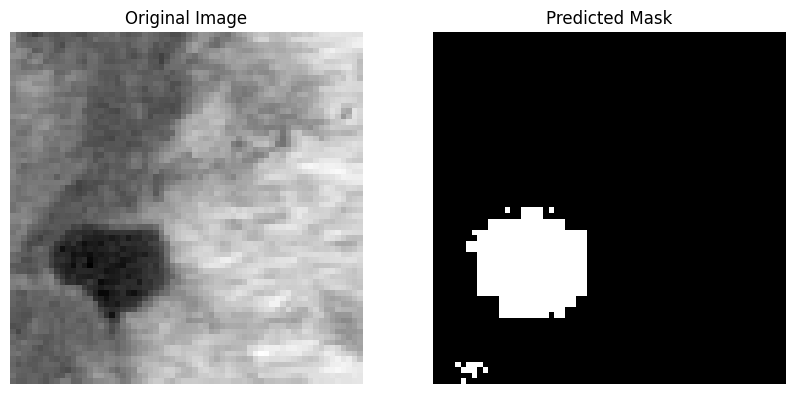

Predicting for patch_11_18.npy...


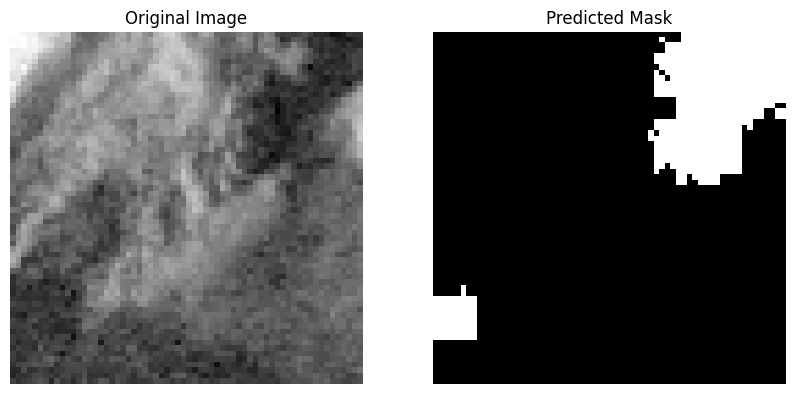

Predicting for patch_11_19.npy...


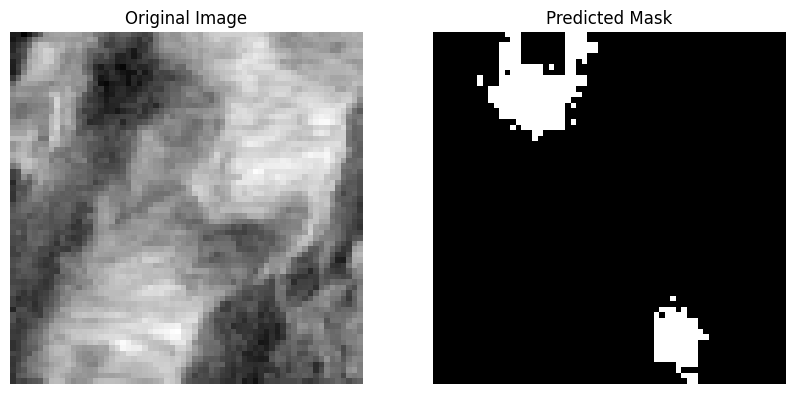

Predicting for patch_11_20.npy...


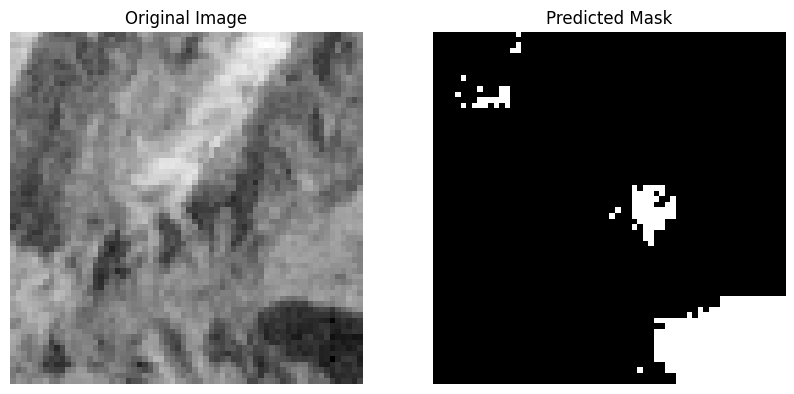

Predicting for patch_11_21.npy...


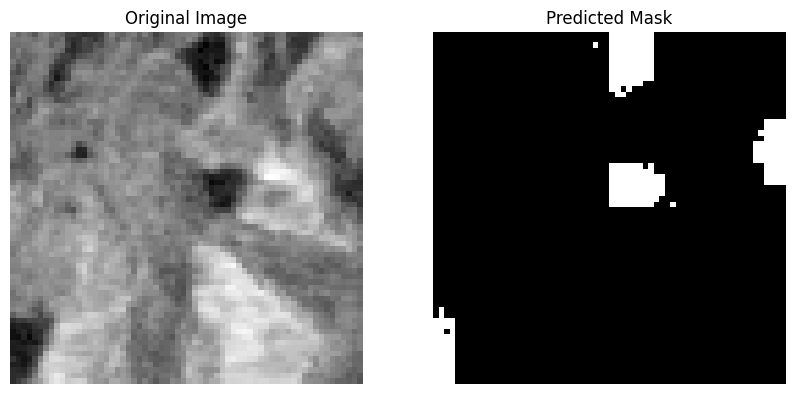

Predicting for patch_11_23.npy...


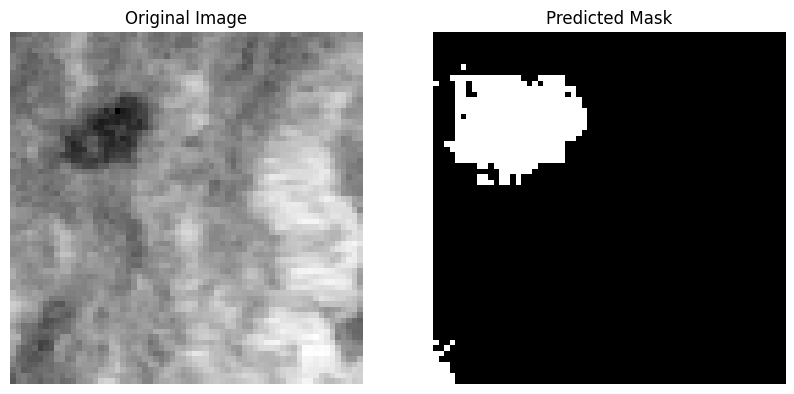

Predicting for patch_11_26.npy...


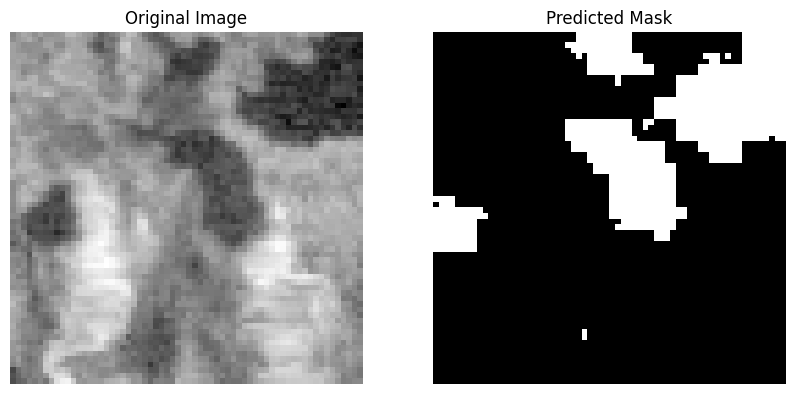

Predicting for patch_11_27.npy...


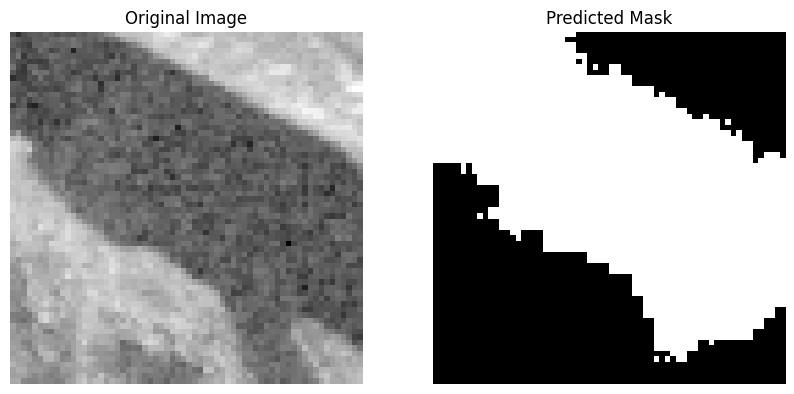

Predicting for patch_11_28.npy...


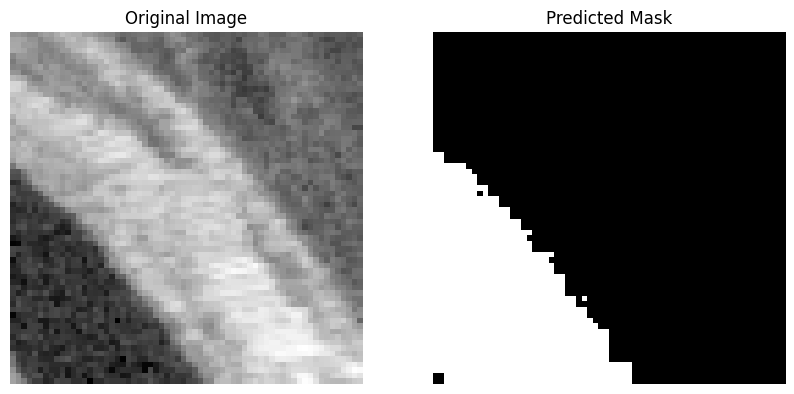

Predicting for patch_12_0.npy...


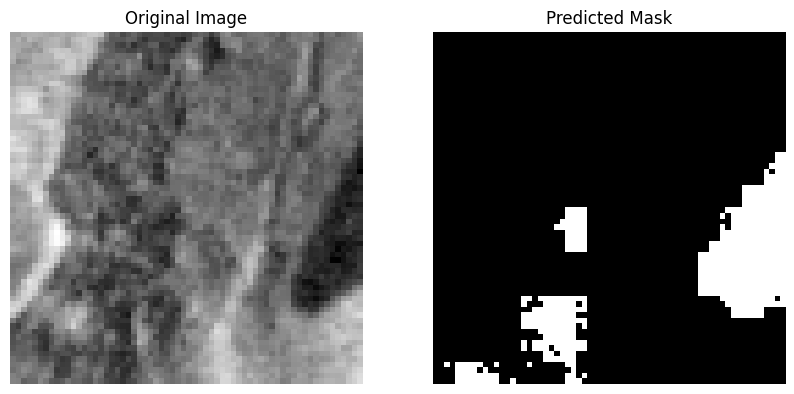

Predicting for patch_12_1.npy...


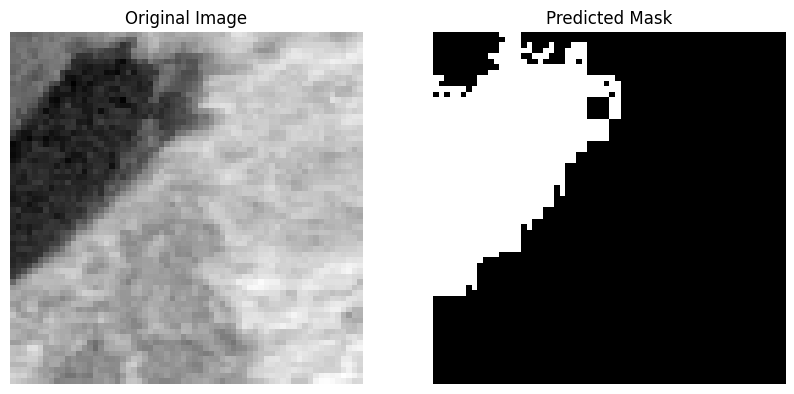

Predicting for patch_12_10.npy...


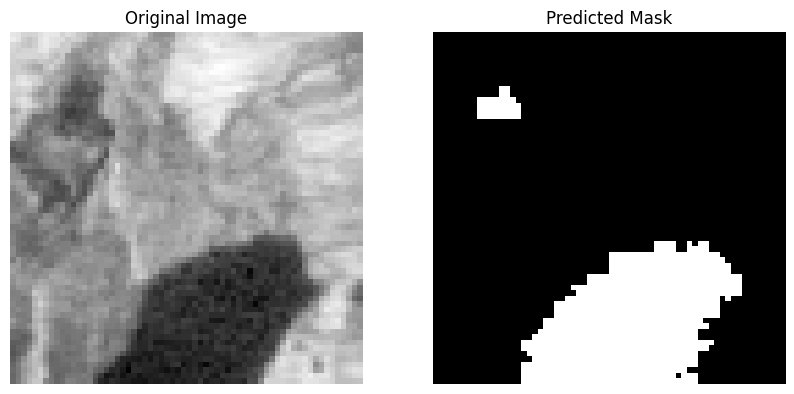

Predicting for patch_12_20.npy...


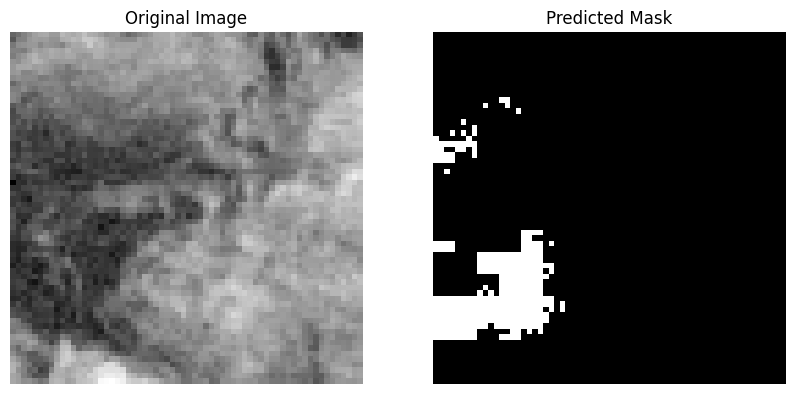

Predicting for patch_12_21.npy...


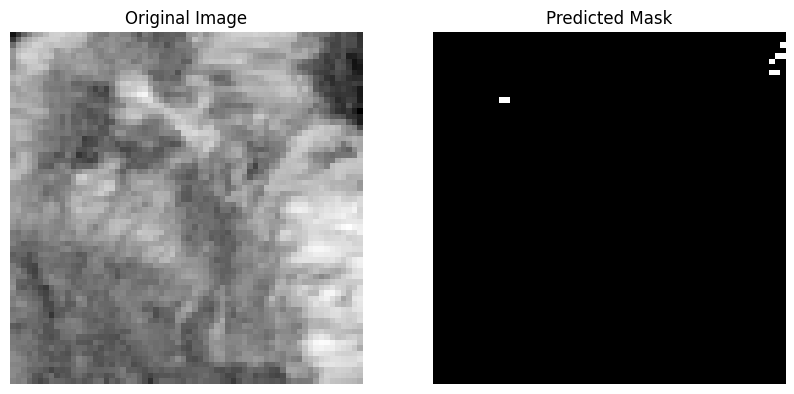

Predicting for patch_12_24.npy...


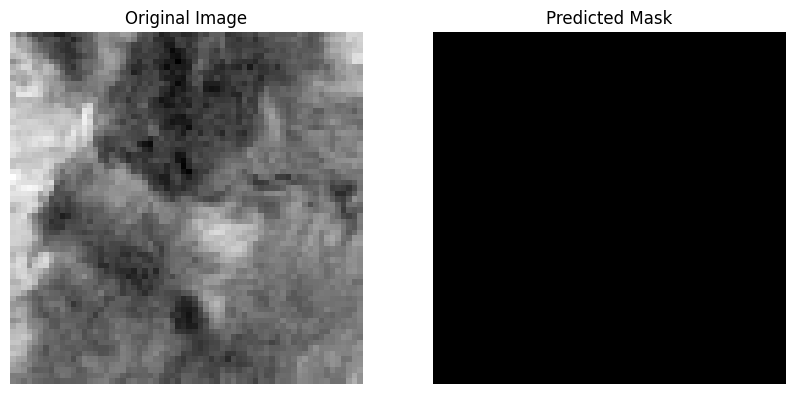

Predicting for patch_12_25.npy...


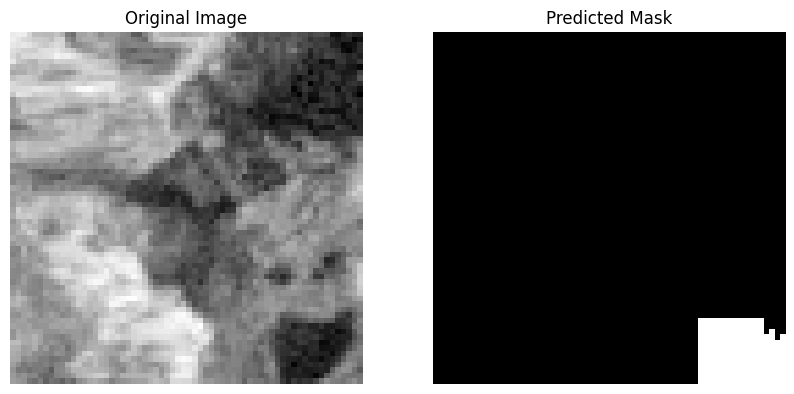

Predicting for patch_12_27.npy...


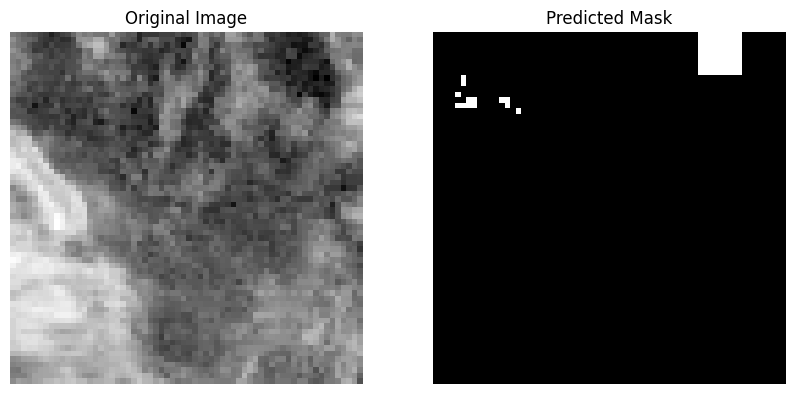

Predicting for patch_12_28.npy...


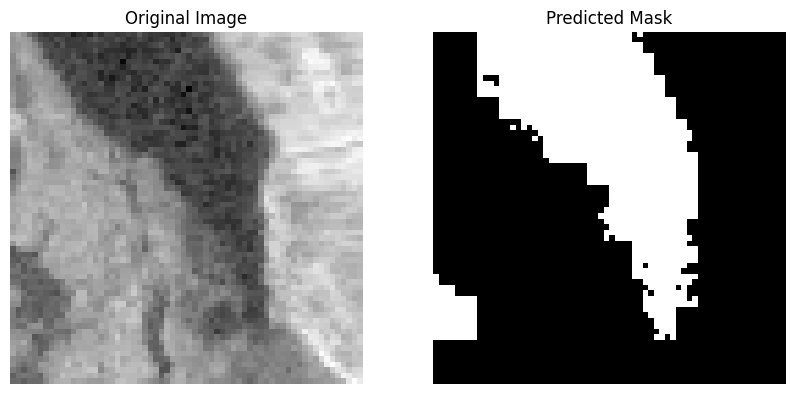

Predicting for patch_13_8.npy...


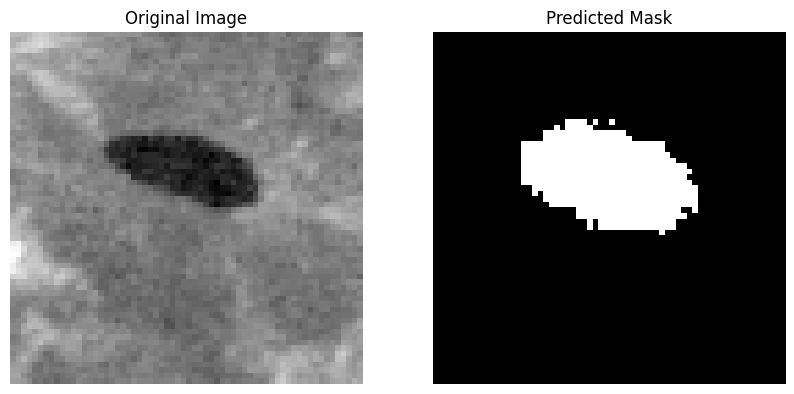

Predicting for patch_13_10.npy...


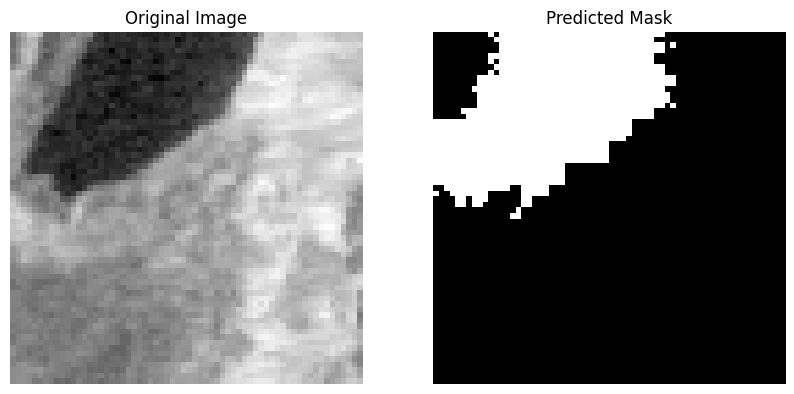

Predicting for patch_13_11.npy...


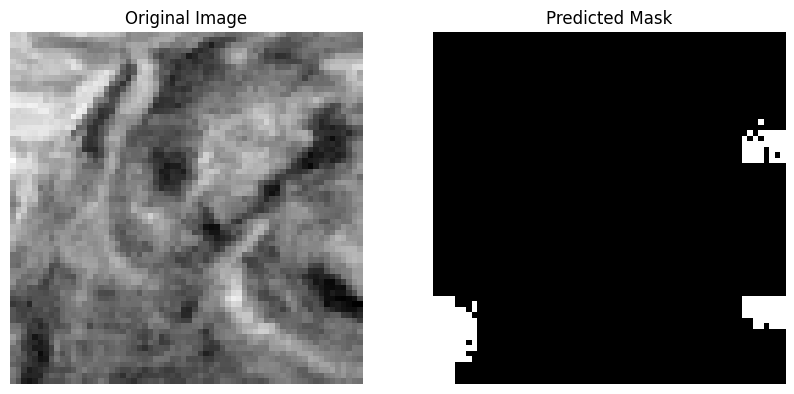

Predicting for patch_13_12.npy...


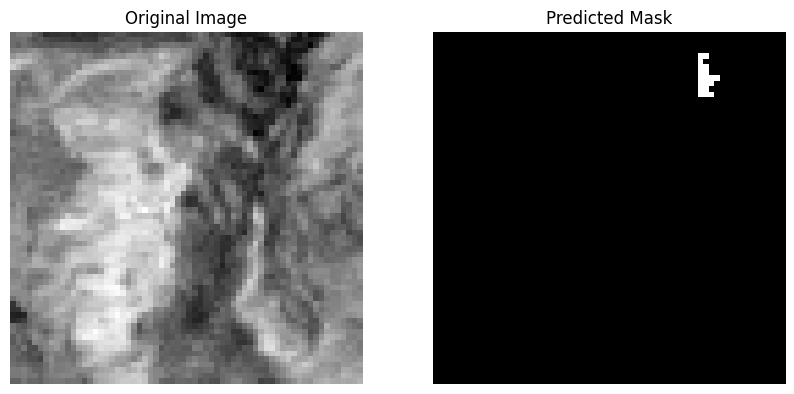

Predicting for patch_13_13.npy...


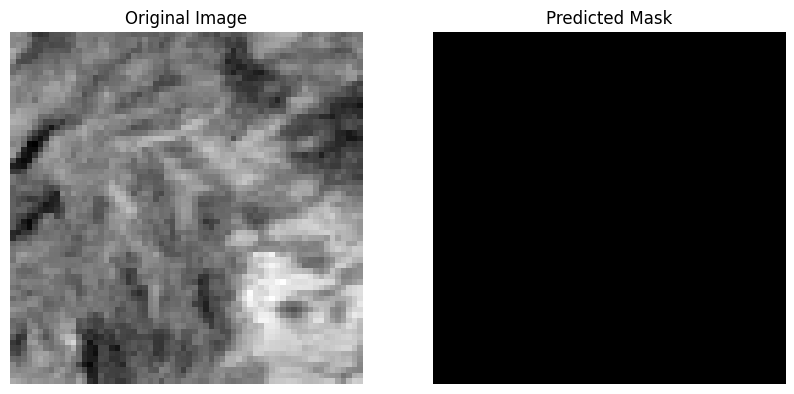

Predicting for patch_13_19.npy...


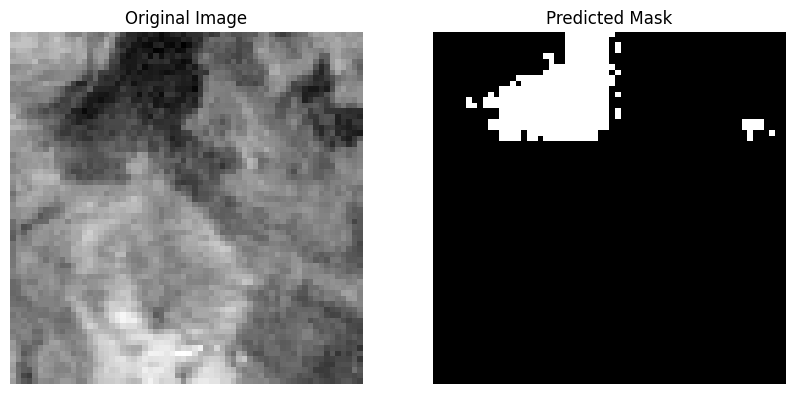

Predicting for patch_13_20.npy...


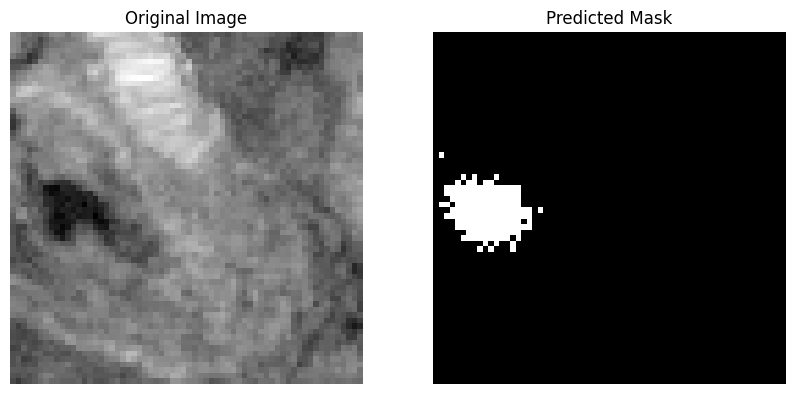

Predicting for patch_13_21.npy...


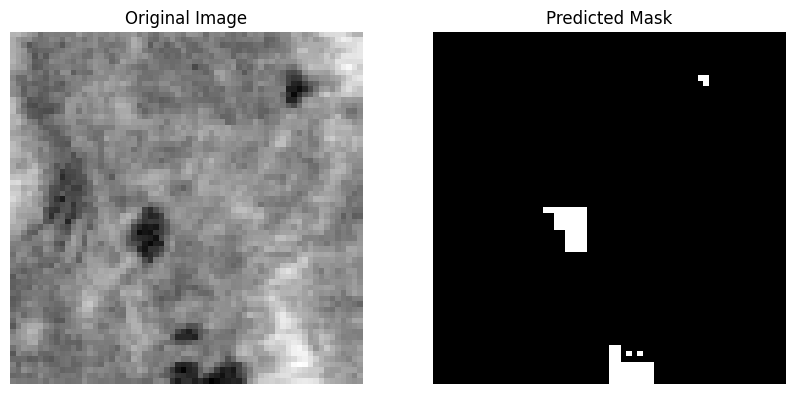

Predicting for patch_13_22.npy...


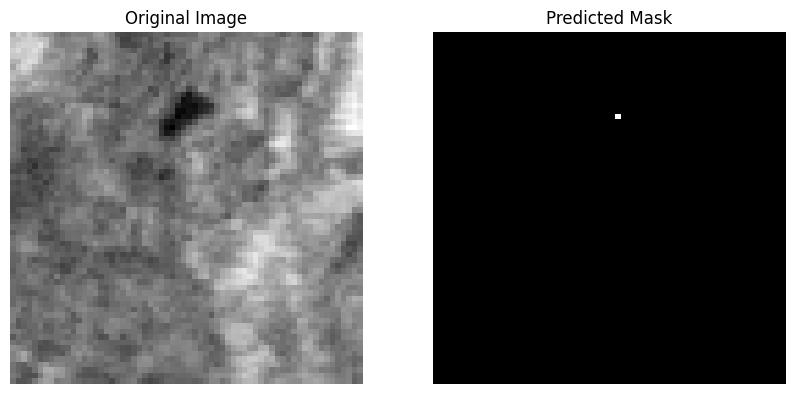

Predicting for patch_13_23.npy...


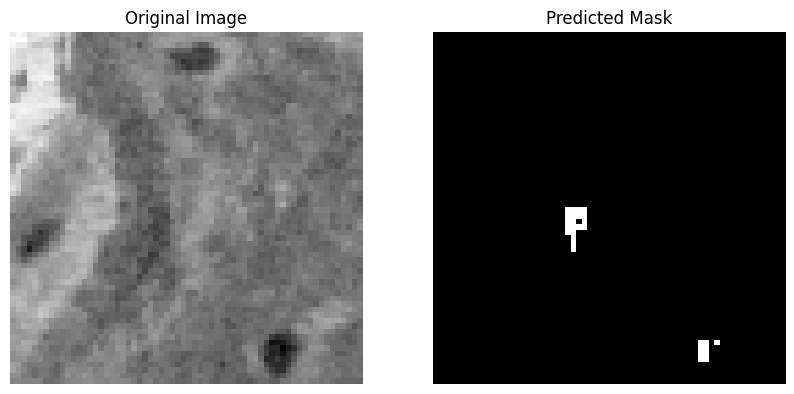

Predicting for patch_13_25.npy...


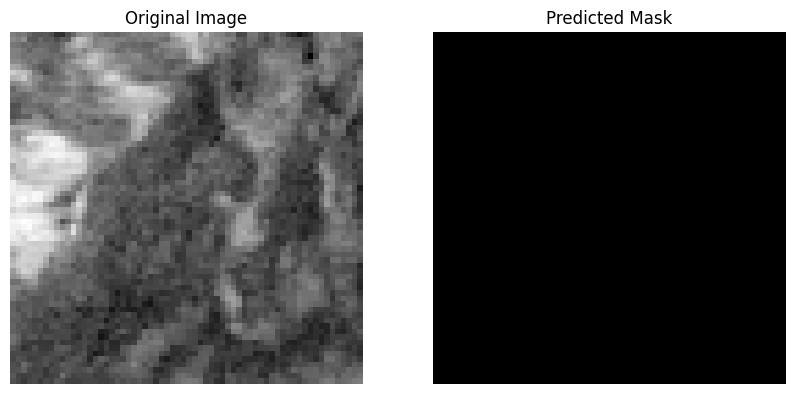

Predicting for patch_13_26.npy...


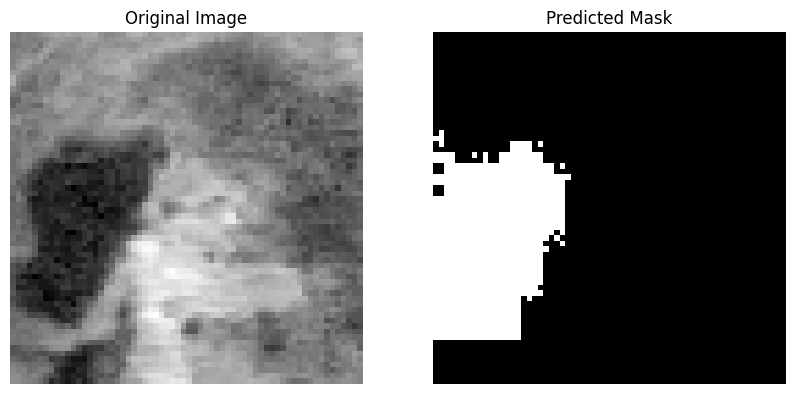

Predicting for patch_14_13.npy...


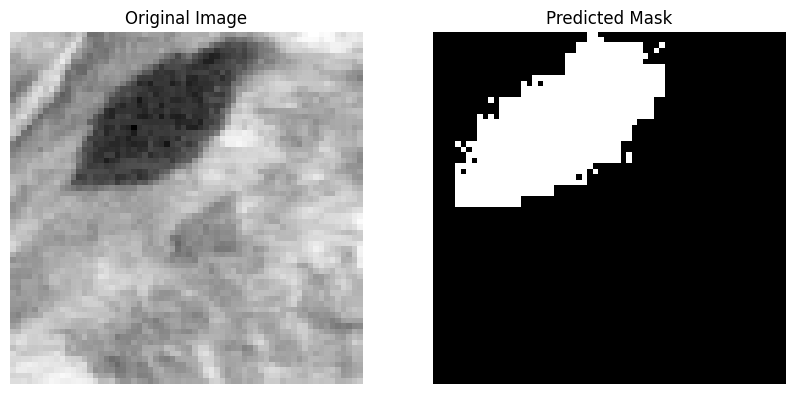

Predicting for patch_14_18.npy...


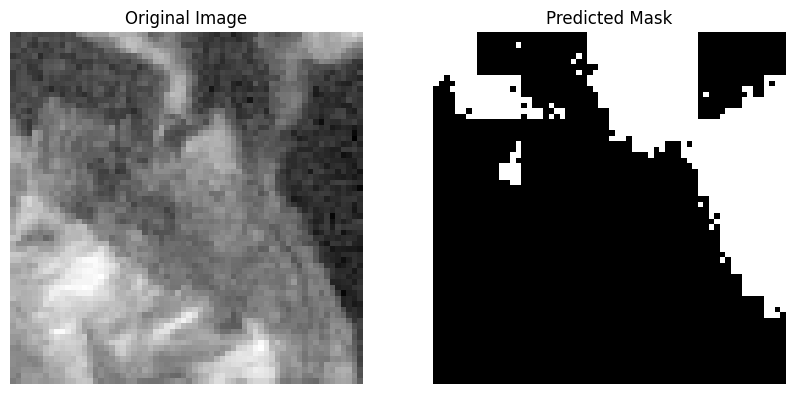

Predicting for patch_14_19.npy...


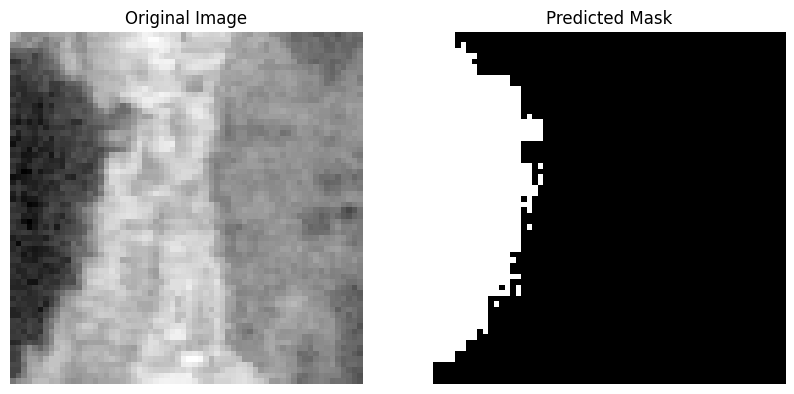

Predicting for patch_14_20.npy...


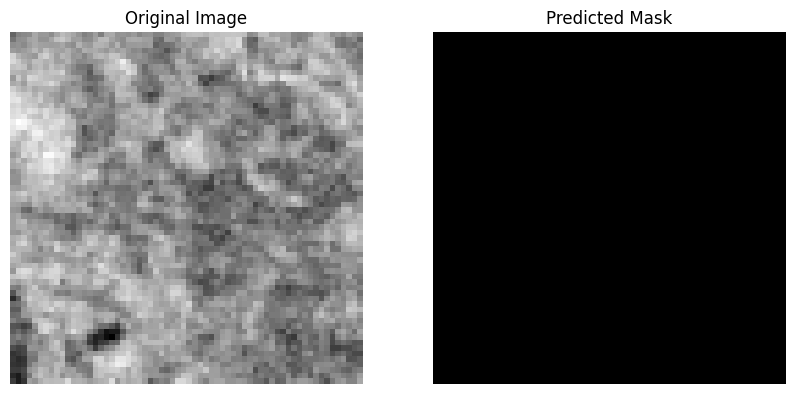

Predicting for patch_14_21.npy...


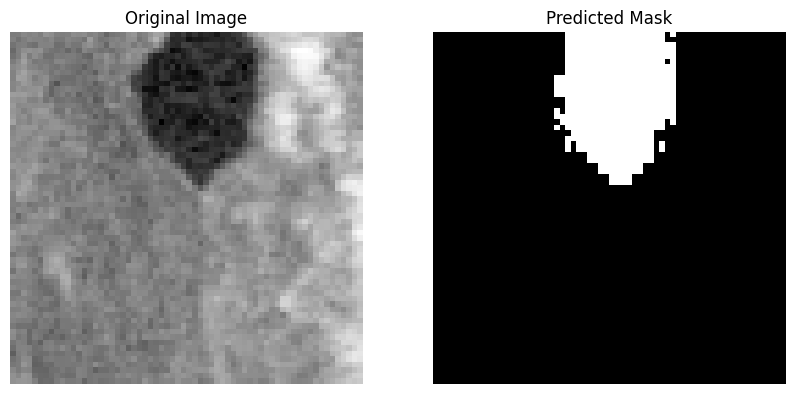

Predicting for patch_14_23.npy...


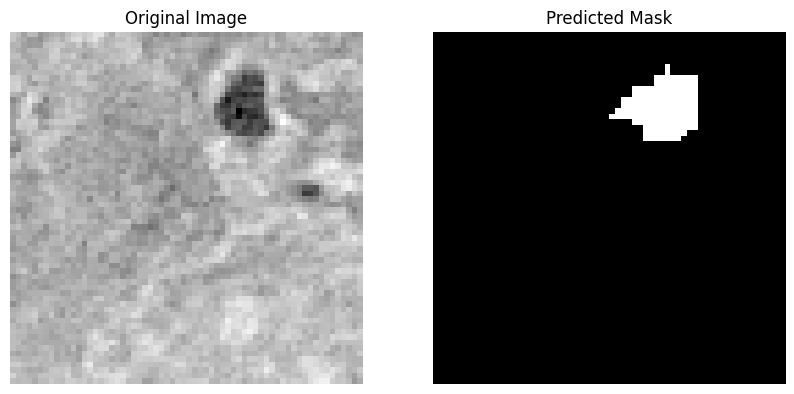

Predicting for patch_14_25.npy...


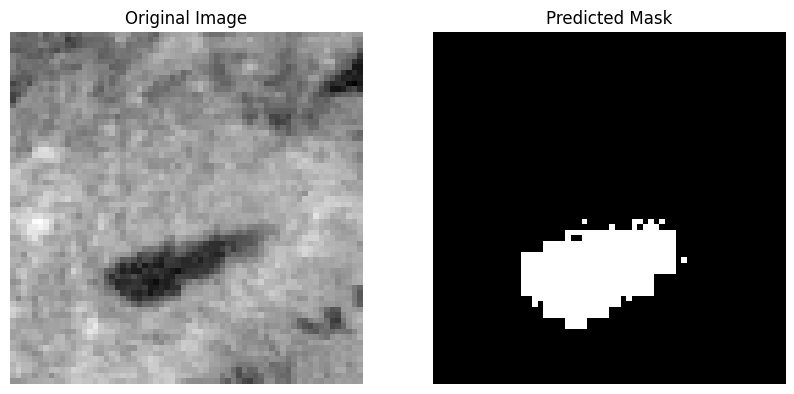

Predicting for patch_14_26.npy...


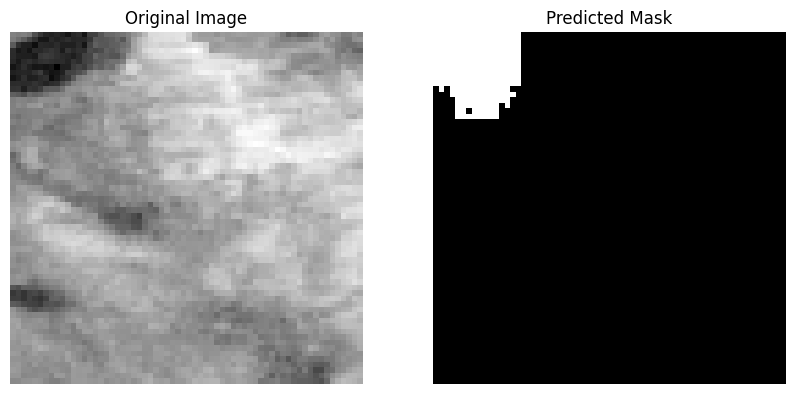

Predicting for patch_15_18.npy...


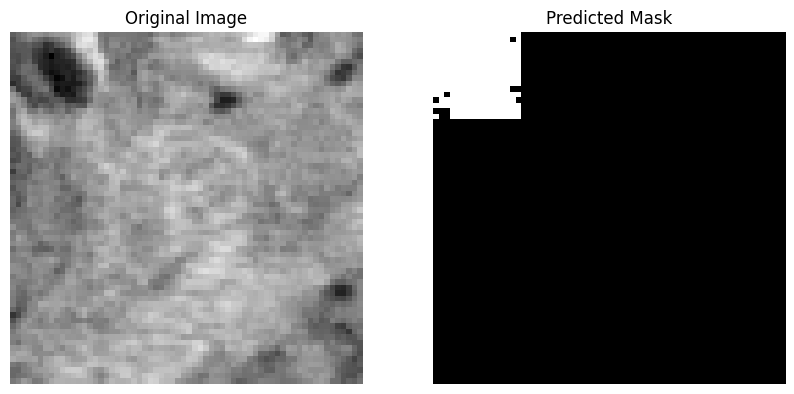

Predicting for patch_15_19.npy...


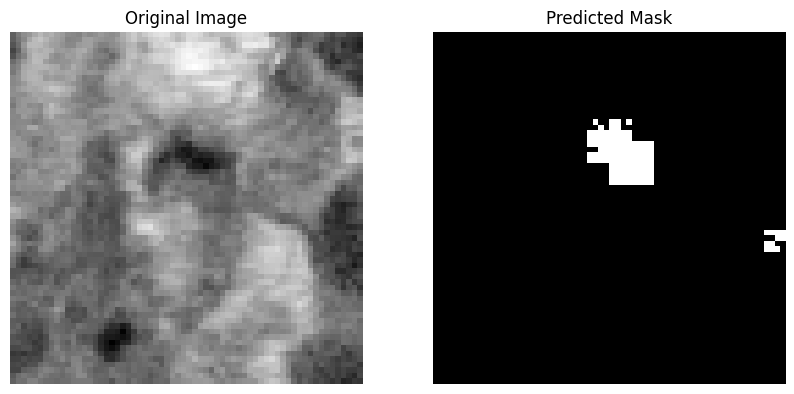

Predicting for patch_15_20.npy...


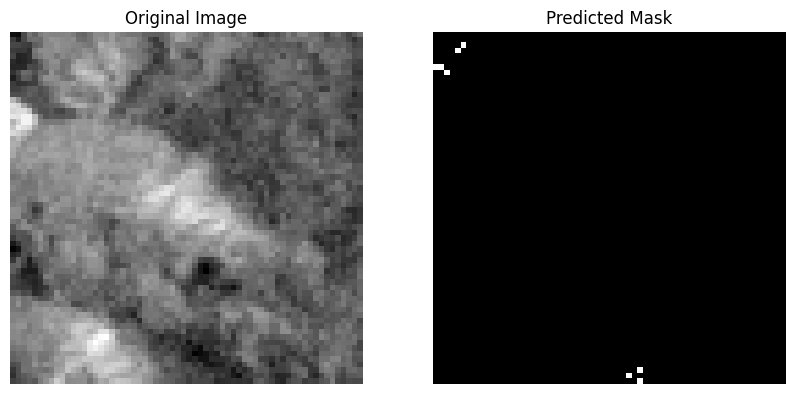

Predicting for patch_16_20.npy...


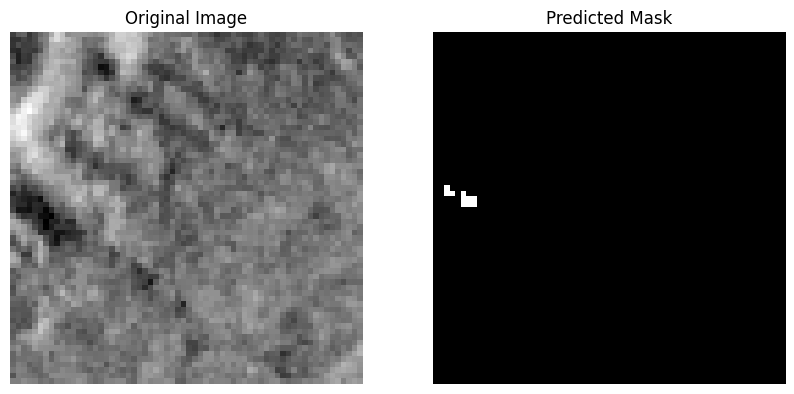

Predicting for patch_16_24.npy...


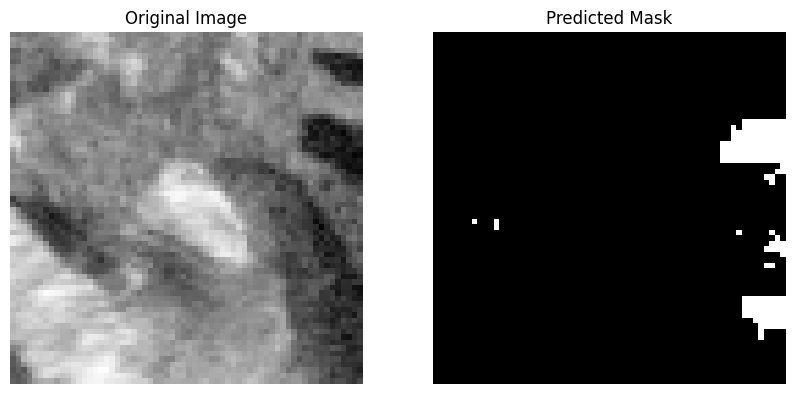

Predicting for patch_16_25.npy...


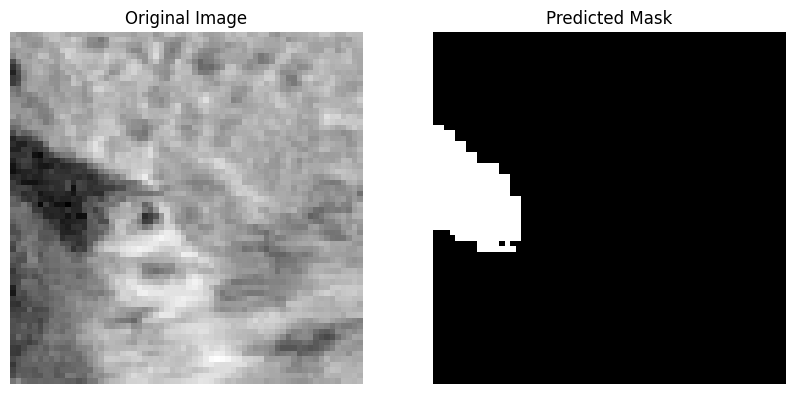

Predicting for patch_17_23.npy...


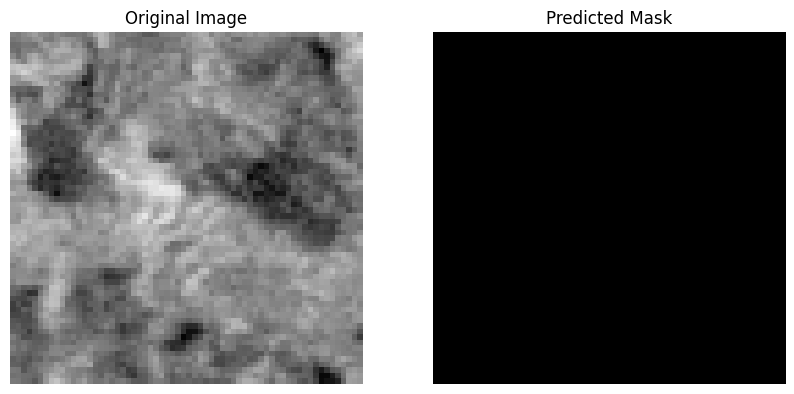

Predicting for patch_17_24.npy...


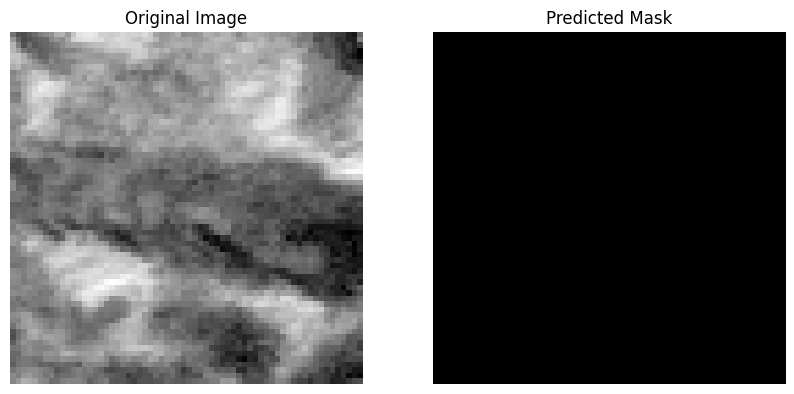

Predicting for patch_18_23.npy...


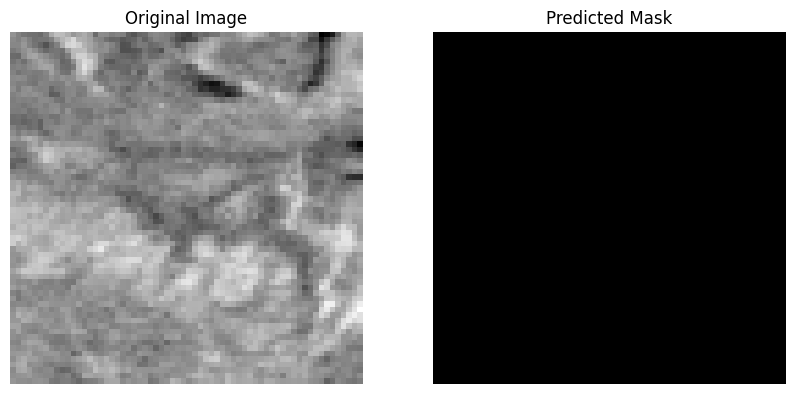

Predicting for patch_18_24.npy...


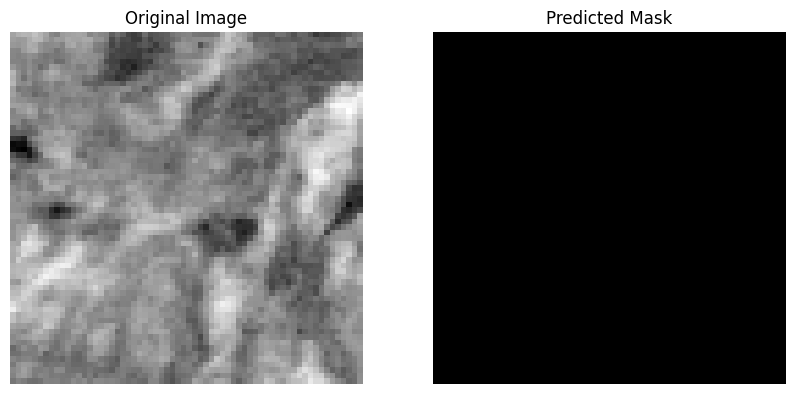

Predicting for patch_19_22.npy...


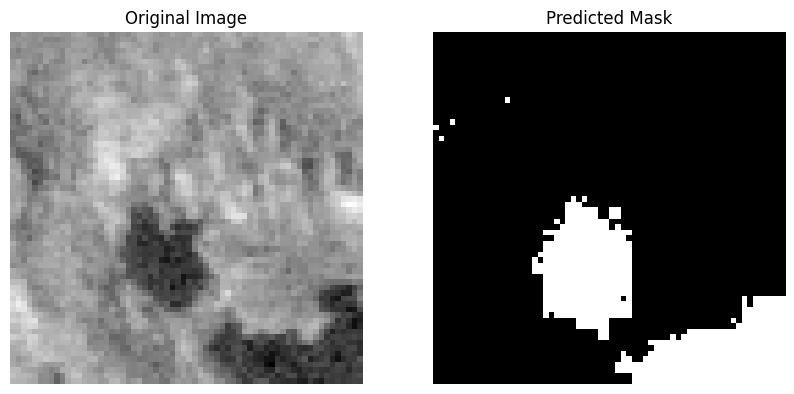

Predicting for patch_19_23.npy...


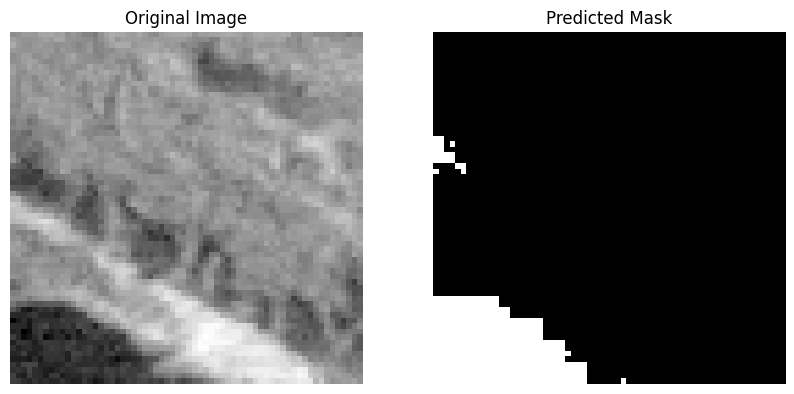

Predicting for patch_19_24.npy...


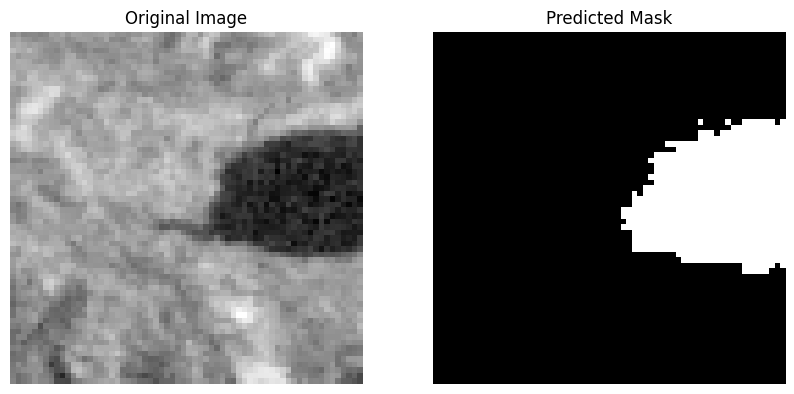

Predicting for patch_19_25.npy...


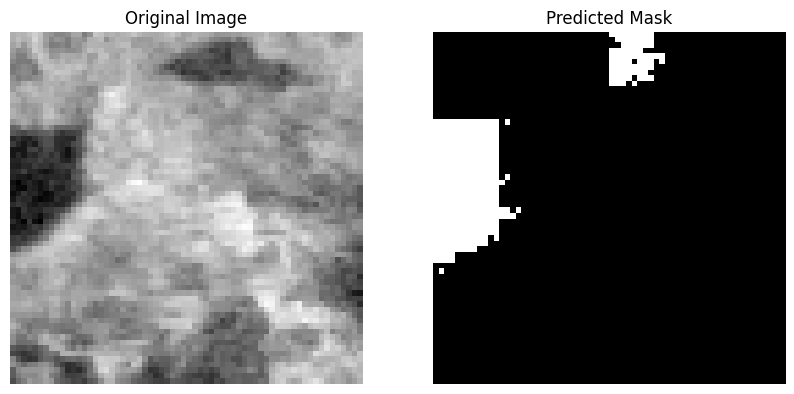

Predicting for patch_20_20.npy...


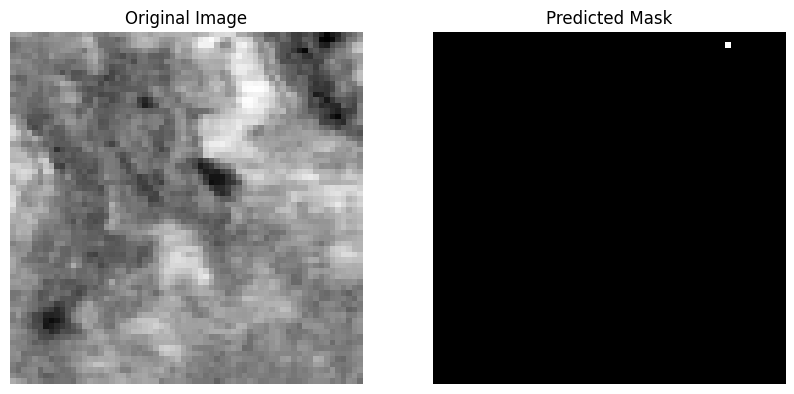

Predicting for patch_20_22.npy...


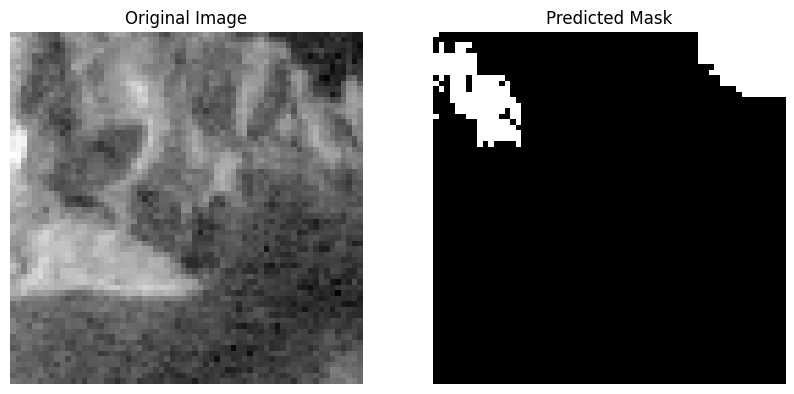

Predicting for patch_20_23.npy...


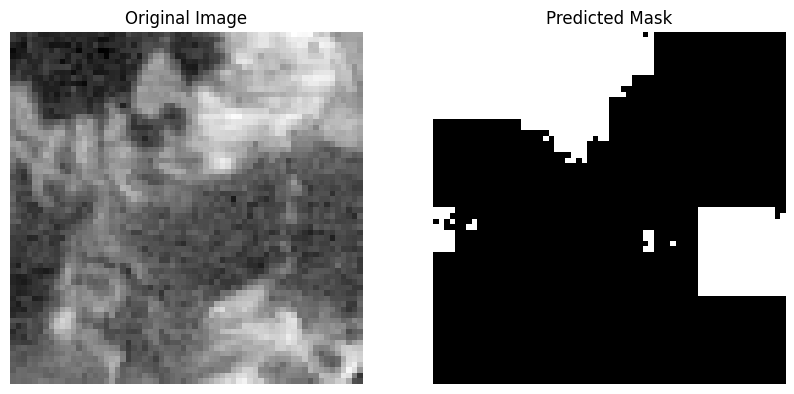

Predicting for patch_20_24.npy...


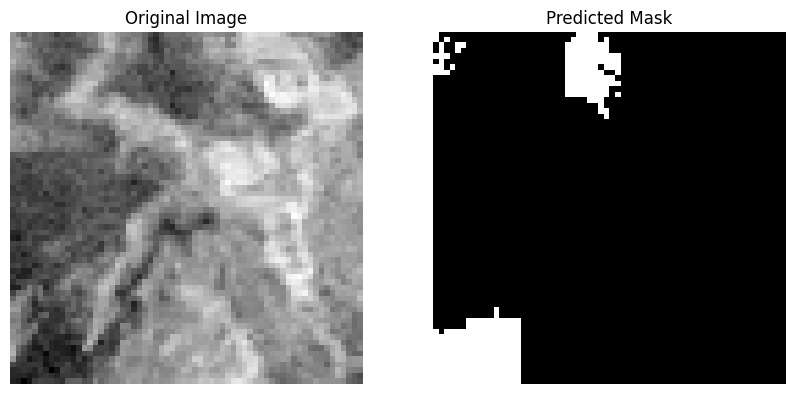

Predicting for patch_21_23.npy...


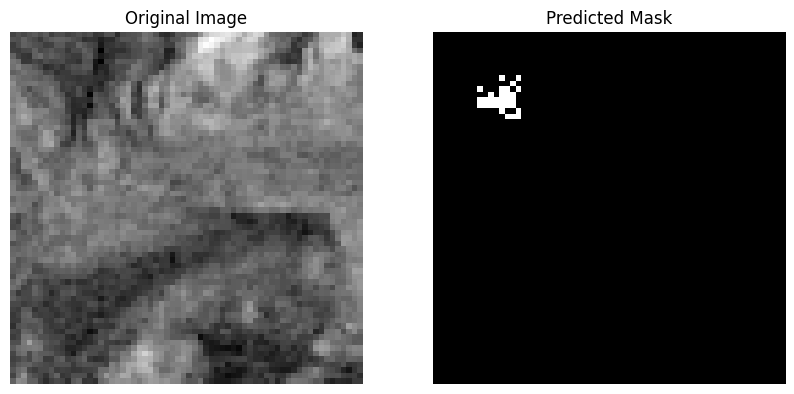

Predicting for patch_21_24.npy...


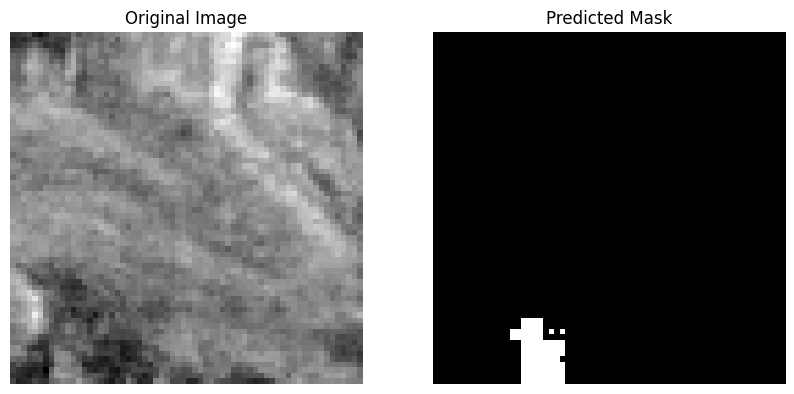

Predicting for patch_21_25.npy...


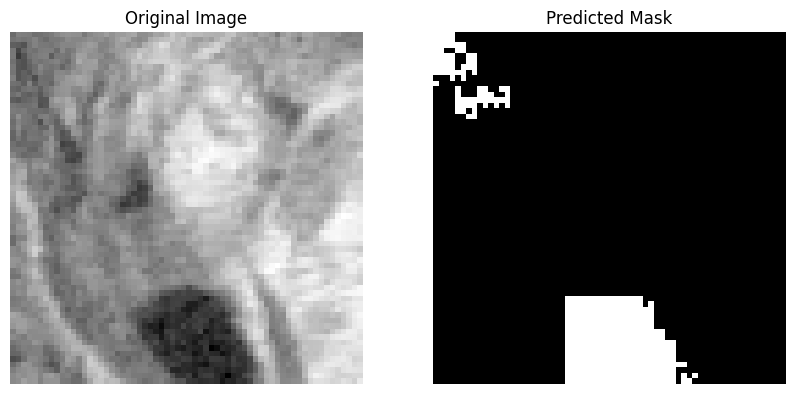

Predicting for patch_21_26.npy...


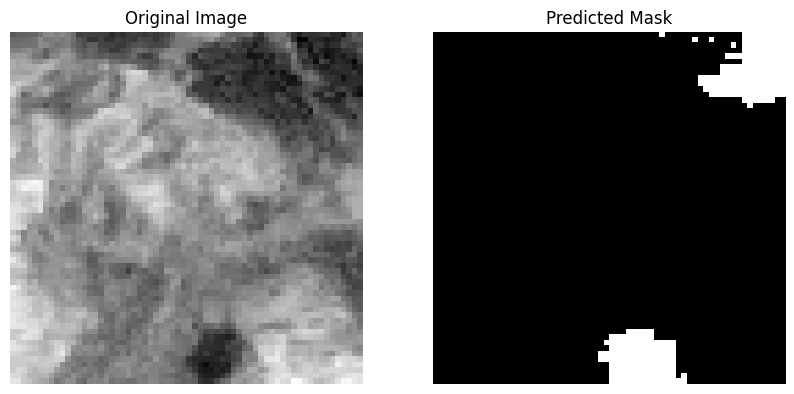

Predicting for patch_22_21.npy...


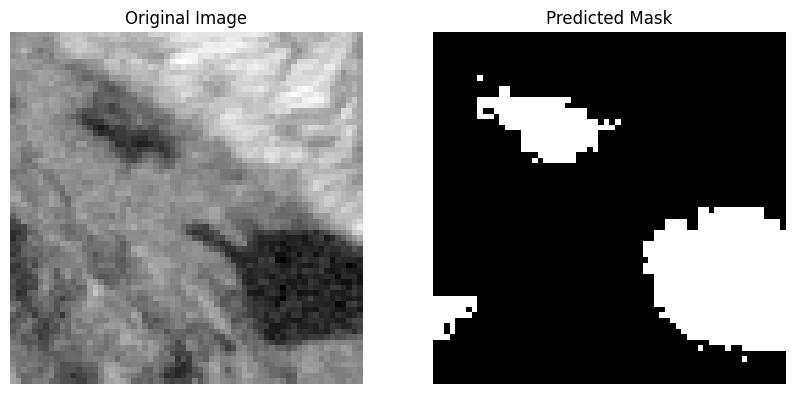

Predicting for patch_22_22.npy...


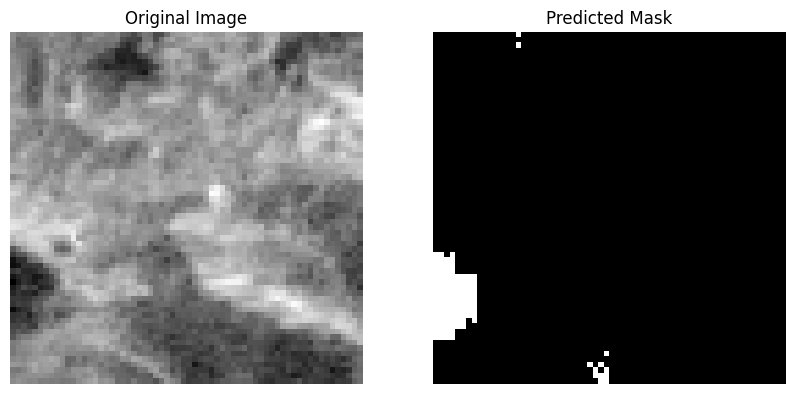

Predicting for patch_22_25.npy...


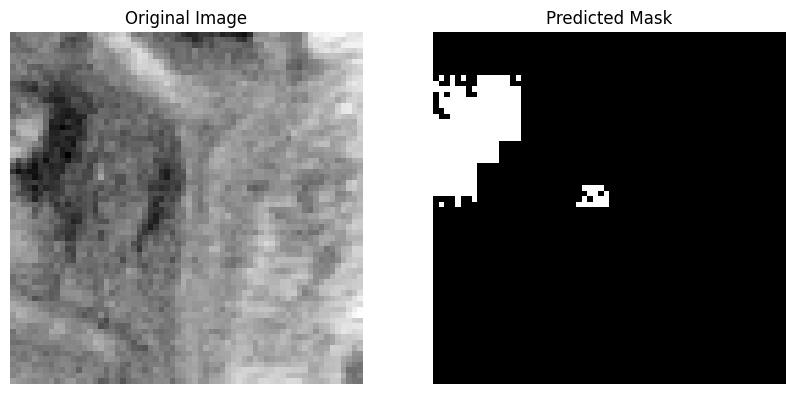

Predicting for patch_22_26.npy...


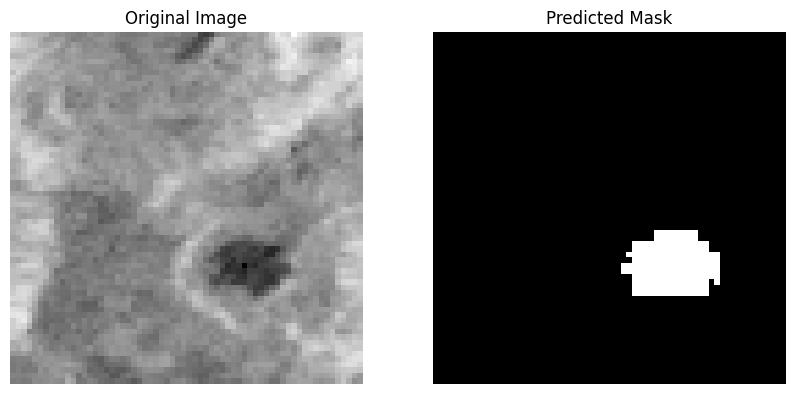

Predicting for patch_22_31.npy...


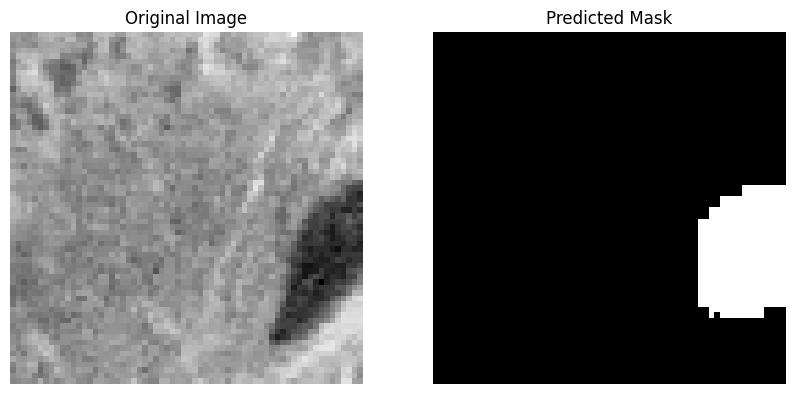

Predicting for patch_22_32.npy...


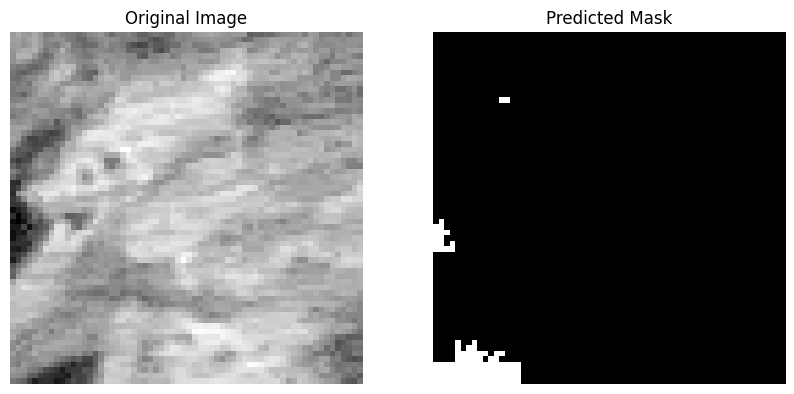

Predicting for patch_23_26.npy...


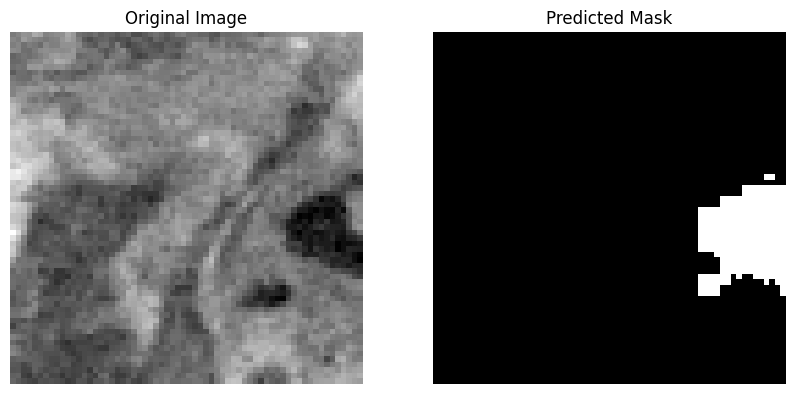

Predicting for patch_23_27.npy...


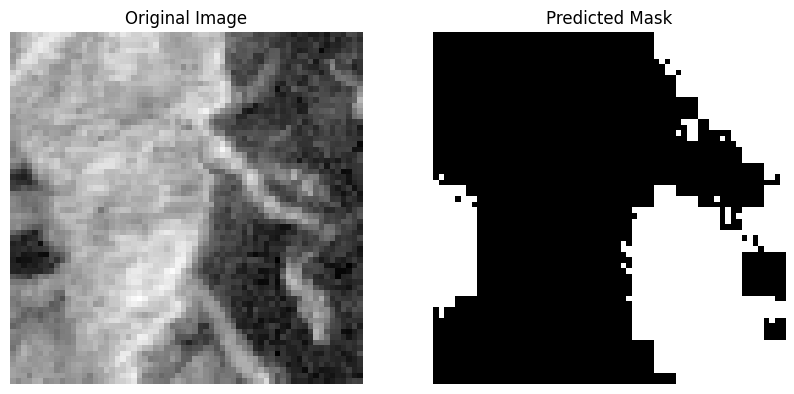

Predicting for patch_23_31.npy...


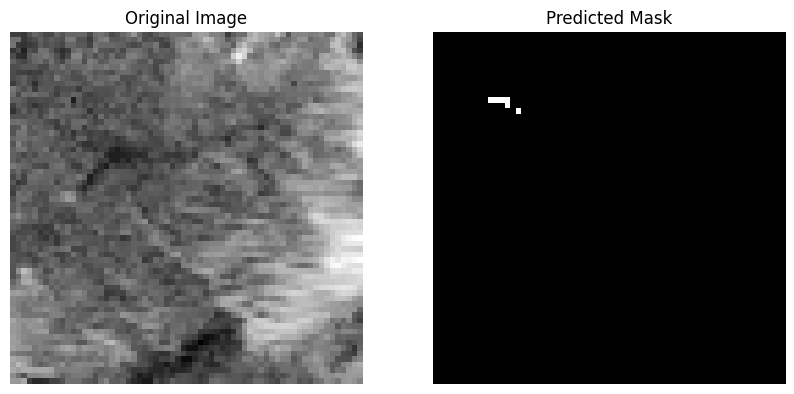

Predicting for patch_23_32.npy...


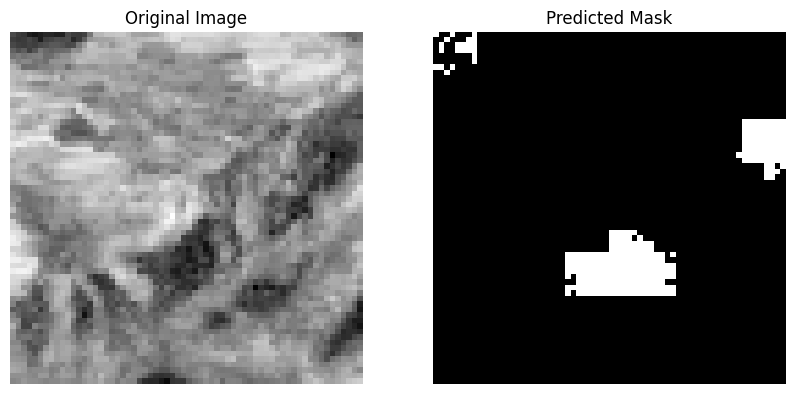

Predicting for patch_23_33.npy...


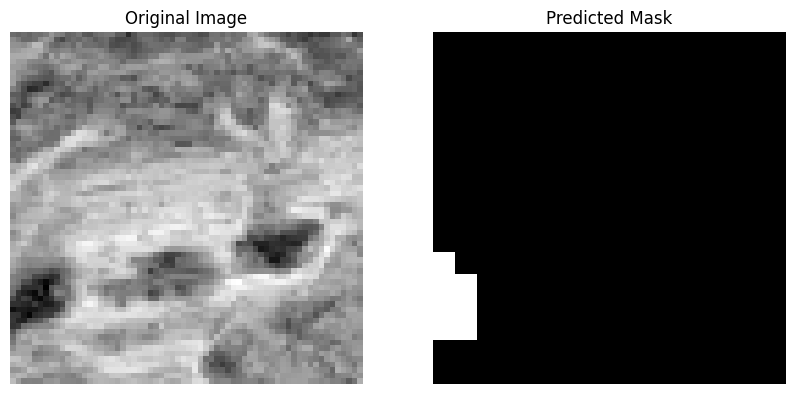

Predicting for patch_24_26.npy...


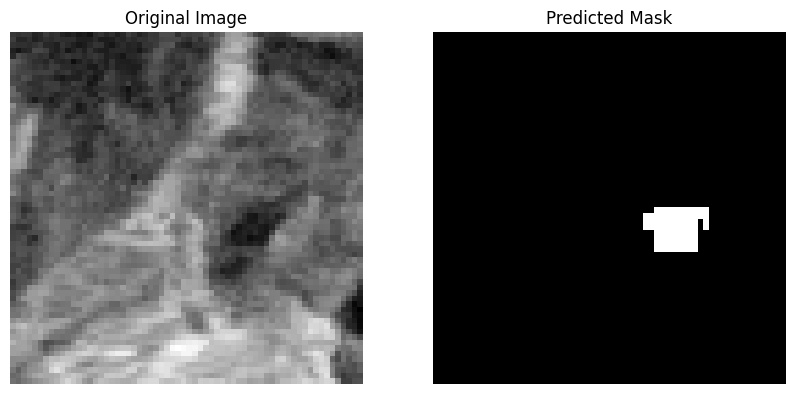

Predicting for patch_24_32.npy...


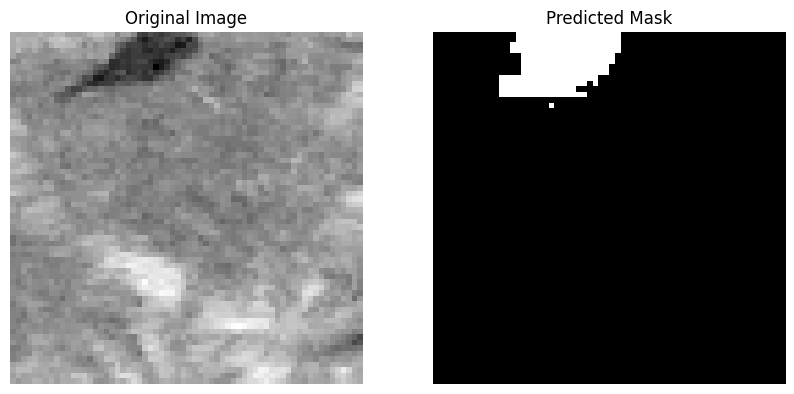

Predicting for patch_25_26.npy...


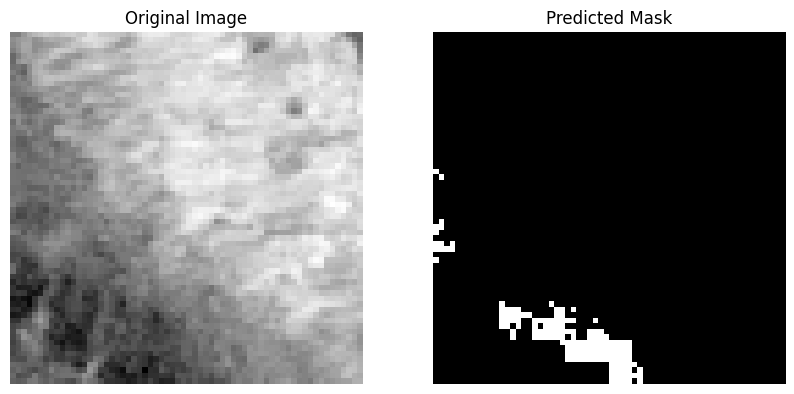

Predicting for patch_26_13.npy...


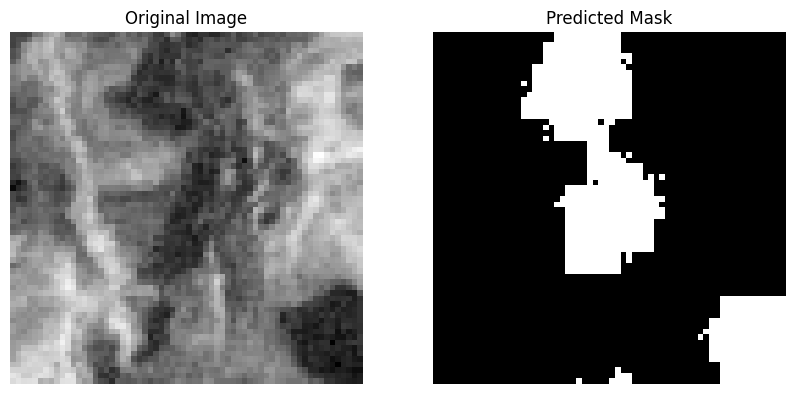

Predicting for patch_26_14.npy...


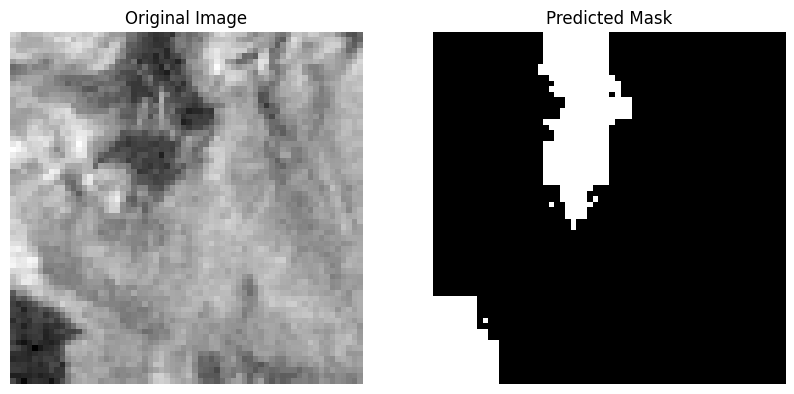

Predicting for patch_26_25.npy...


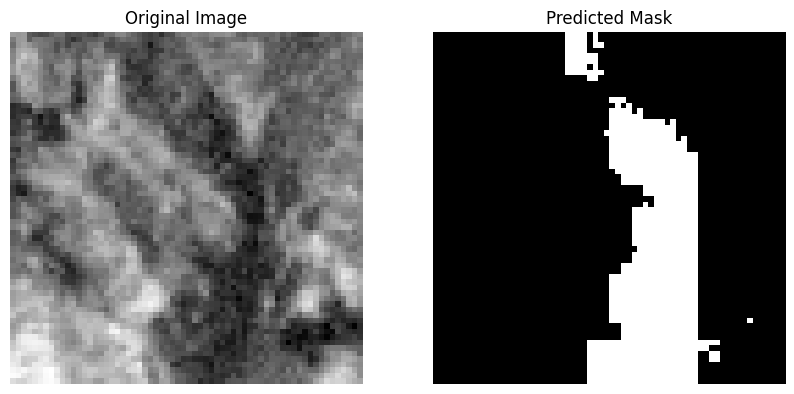

Predicting for patch_26_26.npy...


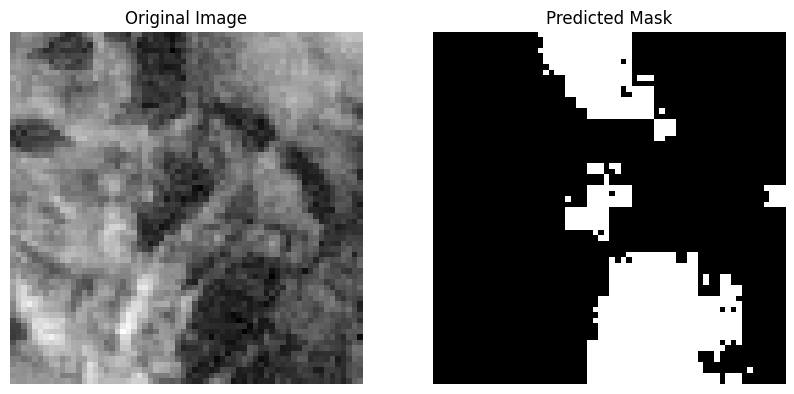

Predicting for patch_26_32.npy...


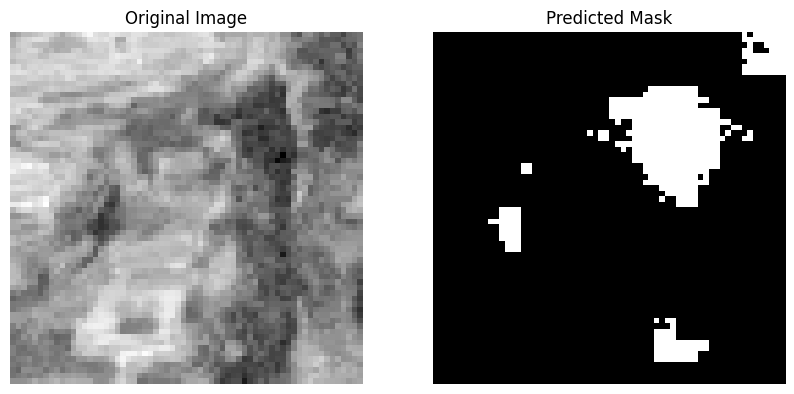

Predicting for patch_26_33.npy...


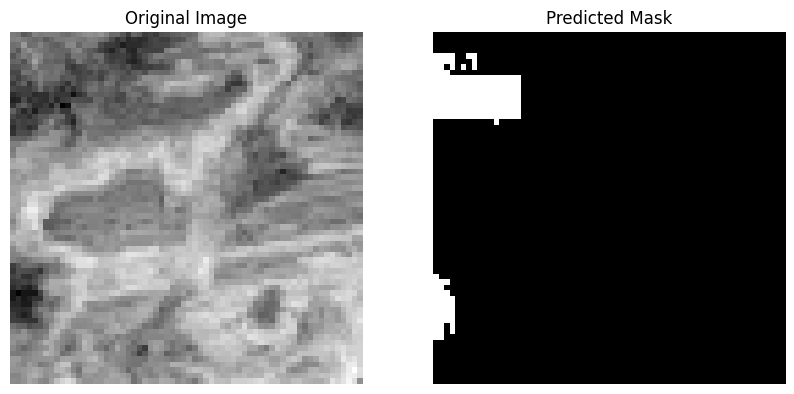

Predicting for patch_27_13.npy...


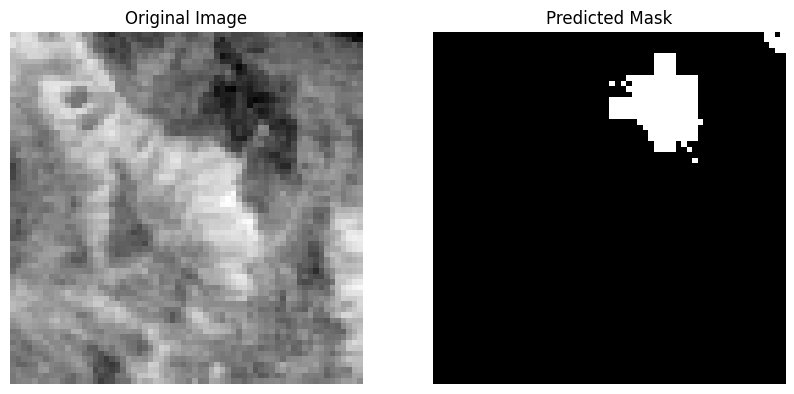

Predicting for patch_27_14.npy...


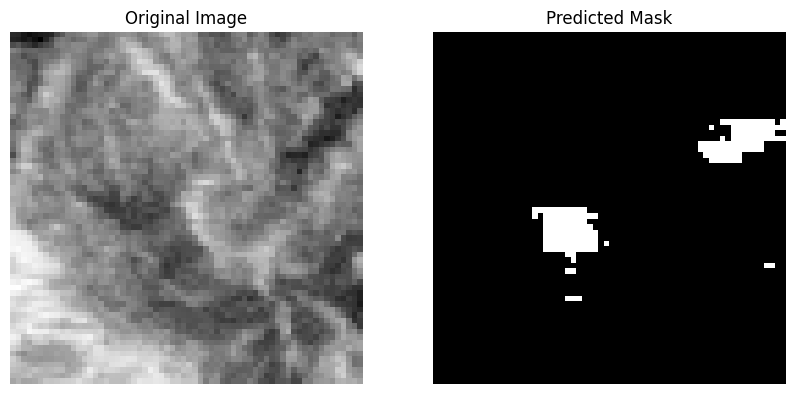

Predicting for patch_27_26.npy...


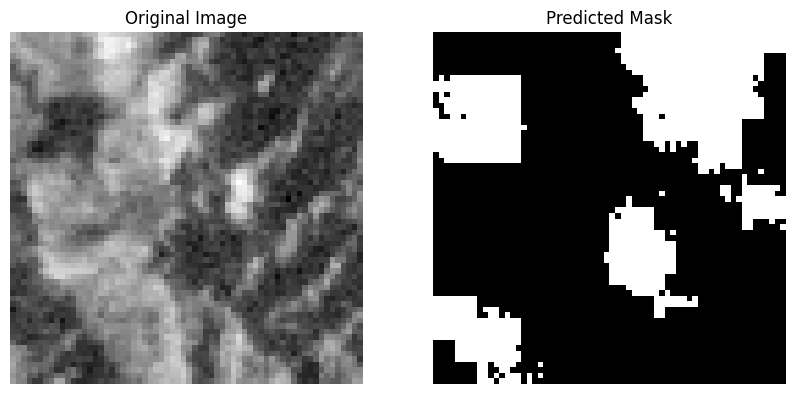

Predicting for patch_27_33.npy...


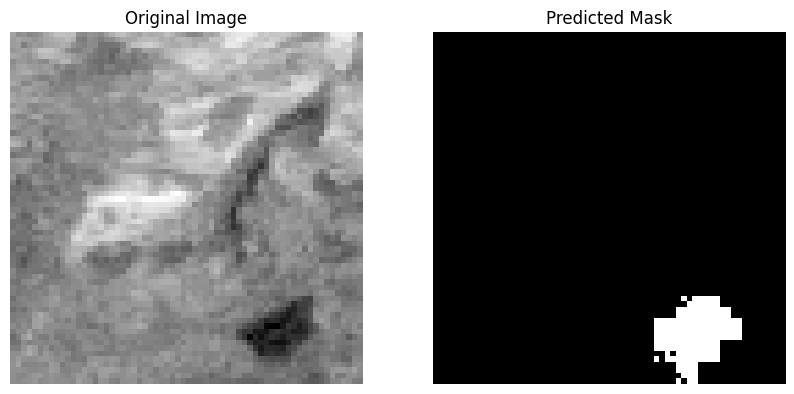

Predicting for patch_28_26.npy...


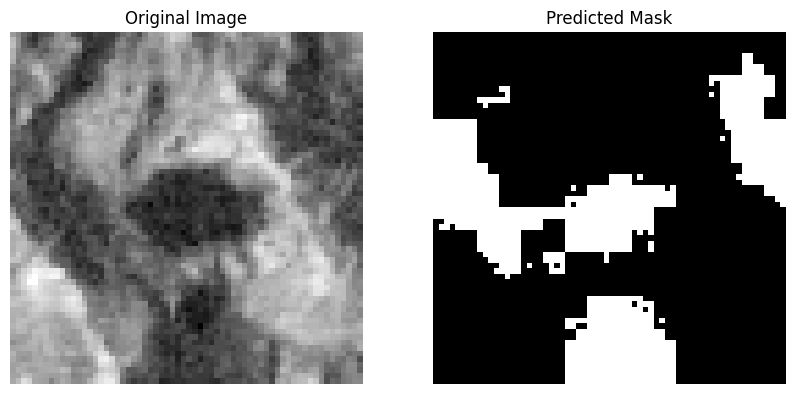

Predicting for patch_30_31.npy...


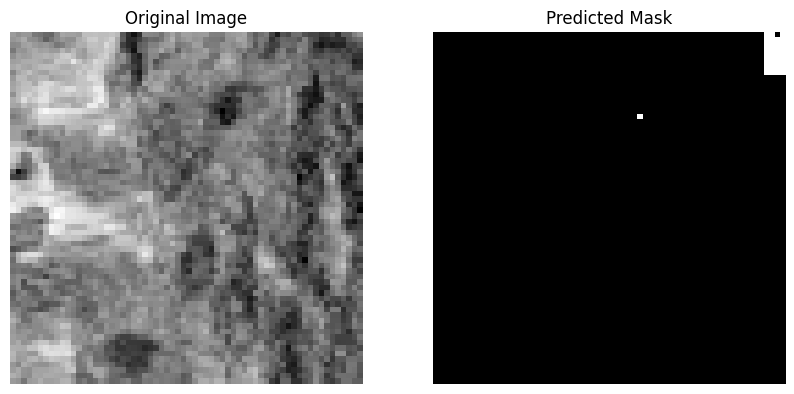

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Define U-Net architecture (same as before)
class UNet(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        # Encoder (downsampling)
        self.enc1 = self.conv_block(n_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)

        # Decoder (upsampling)
        self.dec1 = self.upconv(512, 256)
        self.dec2 = self.upconv(256, 128)
        self.dec3 = self.upconv(128, 64)
        self.dec4 = self.upconv(64, 64)
        self.dec5 = nn.Conv2d(64, n_classes, kernel_size=1)

        # Initialize with kaiming normal
        self.initialize_weights()

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d) or isinstance(module, nn.ConvTranspose2d):
                nn.init.kaiming_normal_(module.weight)

    def conv_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def upconv(self, in_ch, out_ch):
        return nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        # Decoder
        d1 = self.dec1(e4)
        d2 = self.dec2(d1)
        d3 = self.dec3(d2)
        d4 = self.dec4(d3)
        out = self.dec5(d4)

        return torch.sigmoid(out)

# Load the trained model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(n_channels=3, n_classes=1).to(device)
model.load_state_dict(torch.load('/content/drive/MyDrive/lake_segmentation_model_epoch_180.pth'))
model.eval()

# Define the folder where new data is stored
new_data_folder = '/content/drive/MyDrive/rashid_trials/time/2024/filtered/im4'
output_folder = '/content/drive/MyDrive/rashid_trials/time/2024/predictions/im_4'

# Ensure the output folder exists
os.makedirs(output_folder, exist_ok=True)

file_names = [f for f in os.listdir(new_data_folder) if f.endswith('.npy')]
print(file_names)

# Function to make predictions on a single image and save the prediction
def predict_and_save(file_name):
    # Load the image
    image_path = os.path.join(new_data_folder, file_name)
    image = np.load(image_path)

    if image.shape == (64, 64, 3):
        image = np.transpose(image, (2, 0, 1))  # Transpose to (3, 64, 64)

    # Convert to torch tensor
    image = torch.from_numpy(image).float().unsqueeze(0).to(device)

    # Make prediction
    with torch.no_grad():
        output = model(image)
        prediction = (torch.squeeze(output) > 0.25).float().cpu().numpy()

    # Save the prediction as a .npy file
    save_path = os.path.join(output_folder, file_name)
    np.save(save_path, prediction)

    # Optionally, visualize the prediction
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))

    ax[0].imshow(image.cpu().squeeze()[1,:,:], cmap='gray')
    ax[0].set_title('Original Image')
    ax[0].axis('off')

    ax[1].imshow(prediction, cmap='gray')
    ax[1].set_title('Predicted Mask')
    ax[1].axis('off')

    plt.show()

# Iterate over the files and make predictions
for i, file_name in enumerate(file_names[:]):
    print(f'Predicting for {file_name}...')
    predict_and_save(file_name)

In [ ]:
for i in range(4):
    x = len(os.listdir(f'/content/drive/MyDrive/rashid_trials/time/2024/predictions/im_{i+1}'))
    print(x)

90
20
110
124


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
dataset_np_c = np.load('/content/drive/MyDrive/ritu_trials/filt_patches/bin/im1/res1/patch_1.npy')

print(dataset_np_c)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ritu_trials/filt_patches/bin/im1/res1/patch_1.npy'

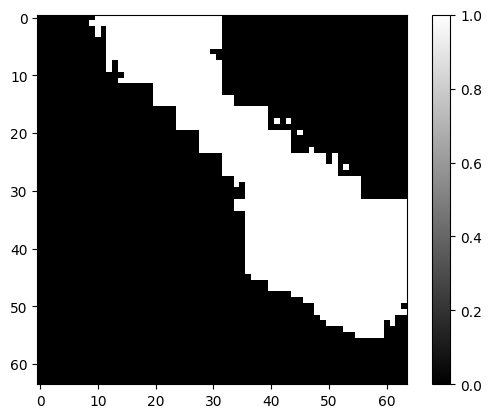

In [ ]:
imshow= plt.imshow(dataset_np_c[:,:], cmap='gray')
plt.colorbar()